# Unsupervised Ranking-Based Hyperspectral Band Selection
## Variance-Based Ranking vs. Entropy-Based Ranking on the DIPCOMA TrainVal dataset

## Section 1 — Project title and objectives

A hyperspectral image (HSI) is a cube $X\in\mathbb{R}^{H\times W\times B}$: $H\times W$ pixels, each with $B$ spectral measurements (bands). Neighbouring bands are often very similar, so we keep only $K<B$ **original** bands.

This notebook implements **exactly two independent, unsupervised ranking methods**:

| | Model A | Model B |
|---|---|---|
| Score of a band | Population **variance** of its pixel values | **Shannon entropy** of its histogram-estimated pixel distribution |
| Ranking | descending variance | descending entropy |
| Output | Top-$K$ original band indices | Top-$K$ original band indices |

Both are compared under **identical** conditions (same cube, same valid-pixel/valid-band policy, same $K$ values, same storage assumptions, same classifier and split).

**Out of scope on purpose:** clustering (K-means, hierarchical), hybrid scores, a combined variance–entropy score, feature weighting, redundancy-based elimination, PCA, autoencoders, GA/PSO, any other ranking. *Redundancy is computed only as an evaluation metric and never influences which bands are selected.* Ground-truth labels are used **only** for downstream classification evaluation, never for ranking.

**How to use (beginner guide)**
1. Run the cells from top to bottom. Each code cell is preceded by a short *what / why / how / output* box.
2. After **Section 5/6** read the printed dataset report. If auto-detection picked the wrong file, axis order or label file, change the matching entry in `CONFIG` (Section 3) and re-run from there.
3. **Nothing in this notebook is a pre-computed result.** Every number appears only when *you* run it on the real data.

## Section 2 — Research methodology and scope

**Primary reference:** Vaddi, R., Phaneendra Kumar, B.L.N., Manoharan, P., Agilandeeswari, L., Sangeetha, V. (2024). *Strategies for dimensionality reduction in hyperspectral remote sensing: A comprehensive overview.* Egyptian Journal of Remote Sensing and Space Sciences 27, 82–92. DOI 10.1016/j.ejrs.2024.01.005.

**Honesty note about the paper.** The review PDF was not available to the assistant that generated this notebook (only your earlier notebook was), so nothing below is quoted from it. The only paper-level statement relied upon is the one your previous notebook already attributed to the review: *ranking-based methods score each band on its own, without modelling interactions between bands* (in contrast to group-wise/clustering methods). **Please verify this and the ranking-method section of the PDF yourself before citing it.** The paper is not claimed to give the formulas, bin counts or protocols used here.

### Classification of every decision in this notebook
| Item | Origin |
|---|---|
| Rank each band individually by a score and keep Top-$K$ | Ranking-method principle (verify against Vaddi et al. 2024) |
| Population variance $\frac1N\sum(x_i-\mu)^2$ | Standard mathematical definition |
| Shannon entropy $H=-\sum p_i\log_2 p_i$ | Standard definition (Shannon, 1948, *Bell System Technical Journal* 27) |
| Probabilities from a histogram with **common bin edges** over the global valid intensity range | **Our engineering decision** (needed so entropies of different bands are comparable) |
| 256 bins (configurable) | **Our engineering decision**; sensitivity is tested in Section 18 |
| Variance on raw (un-normalised) values | **Our decision**, justified in Section 7 |
| Valid-pixel mask, constant-band exclusion | **Our decision** (documented; nothing dropped silently) |
| Linear spectral interpolation for reconstruction metrics (only with real wavelengths) | **Our evaluation decision**; *not* part of either ranking |
| Block-wise spatial train/test split for classification | **Our evaluation decision** (reduces spatial leakage) |
| Metric definitions (CR, bpp, PSNR, SSIM, SAM, MAE, MRE, redundancy) | Standard definitions / our explicit choices stated in each section |

### Why variance and entropy are reasonable (but not guaranteed) criteria
* **Variance** measures how strongly a band's values spread around its mean. A band with almost constant values carries little contrast between pixels.
* **Entropy** measures the uncertainty of the *distribution* of values: a flat, spread-out histogram has high entropy, a histogram concentrated in a few bins has low entropy.
* **Caveats:** both scores look at one band at a time, so top-ranked bands can be highly correlated (redundant). Noisy bands often have **high** variance and **high** entropy. Neither score uses class information, so neither guarantees better classification or reconstruction.

## Section 3 — Importing libraries and environment setup

All adjustable choices live in one `CONFIG` dictionary (including Top-K values, histogram bins and dataset paths). Edit values here, then re-run.

**What this cell does:** imports every library the notebook uses.  
**Why it is needed:** later cells call NumPy, SciPy, scikit-learn, scikit-image, pandas and Matplotlib; missing packages must be detected early.  
**How it works:** plain `import` statements; psutil and h5py are optional and only checked, not required.  
**Expected output:** one line with library versions and one line saying which optional packages exist. Kaggle and Colab already ship all required packages.

In [1]:
import os, sys, json, time, re, math, hashlib, warnings, platform, tracemalloc, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import io as sio
from scipy.stats import spearmanr
import sklearn
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, recall_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import skimage
from skimage.metrics import structural_similarity
try:
    import psutil
except ImportError:
    psutil = None
try:
    import h5py
except ImportError:
    h5py = None

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__, "| skimage", skimage.__version__, "| pandas", pd.__version__)
print("optional: psutil", psutil is not None, "| h5py", h5py is not None, "(h5py is only needed for MATLAB v7.3 / HDF5 files: pip install h5py)")

python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sklearn 1.6.1 | skimage 0.25.2 | pandas 2.3.3
optional: psutil True | h5py True (h5py is only needed for MATLAB v7.3 / HDF5 files: pip install h5py)


**What this cell does:** defines every adjustable setting (Top-K, histogram bins, split, paths) and creates the output folders.  
**Why it is needed:** one place for all choices makes the experiment reproducible and easy to change; the seed makes random steps repeatable.  
**How it works:** a Python dictionary `CONFIG`; folders are created under `/kaggle/working` (Kaggle) or the current folder (Colab/local).  
**Expected output:** the path of the output folder.

In [2]:
# ===================== CONFIGURATION (edit here) =====================
CONFIG = dict(
    # ---- data location / format (None = auto-detect; adjust after reading the Section 5/6 report) ----
    data_root=None,            # folder containing the dataset
    kaggle_slug="krrishshandilya/dipcoma-trainval",
    try_kagglehub=True,        # fallback download if nothing is found locally (needs credentials/internet)
    image_path=None,           # explicit path of the hyperspectral file to use
    image_index=0,             # otherwise: index into the discovered cube-file list (ONE cube is analysed)
    array_key=None,            # variable name inside .mat/.npz/.h5 files
    axis_order=None,           # e.g. "HWB", "BHW", "HBW" if the automatic guess is wrong
    wavelengths=None,          # list of wavelengths (one per ORIGINAL band) to override auto-detection
    label_path=None, label_key=None, label_background=0,    # ground-truth map (H x W); 0 = unlabeled
    original_bits=None,        # None -> derived from the stored dtype (uint16 -> 16)
    # ---- Top-K design (identical for both models) ----
    retention_percent=[5, 10, 15, 20, 25],   # K = round(percent/100 * B_total), at least 1
    K_list=None,               # e.g. [5,10,15,20,25]; if not None it OVERRIDES retention_percent
    seed=42,
    # ---- preprocessing ----
    const_std_tol=1e-8,        # band is 'constant' if std <= tol * global data range (excluded + reported)
    n_sample_pixels=100_000,   # pixels used ONLY for the redundancy (correlation) evaluation metric
    # ---- Model B (entropy) ----
    entropy_bins=256,          # number of histogram bins, identical for every band
    entropy_bin_sensitivity=[32, 64, 128, 512],   # diagnostic only; [] to skip
    # ---- reconstruction-based metrics (optional evaluation component) ----
    run_reconstruction=True,
    allow_index_interp=False,  # False: reconstruction needs REAL wavelengths; True: use band index as coordinate
    compute_ssim=True, rel_err_eps_frac=1e-4,
    # ---- classification (only if a valid label map exists) ----
    run_classification=True, split_block=32, train_block_fraction=0.5,
    max_train_pixels=20_000, max_test_pixels=30_000, svm_C=10.0, svm_kernel="rbf",
    # ---- runtime / memory / export ----
    timing_repeats=3, measure_memory=True,
    export_cubes="all",        # "all" = reduced cube for every K, "ref" = only the reference K, "none"
)
if os.environ.get("HSI_CONFIG_OVERRIDE"):       # optional JSON override for automated runs
    CONFIG.update(json.loads(os.environ["HSI_CONFIG_OVERRIDE"]))

OUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./")
OUT = OUT_ROOT / "hsi_ranking_outputs"
DIRS = {n: OUT / n for n in ["figures", "tables", "rankings", "selected_bands", "reduced_cubes", "reports", "config"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
FIG_DIR, TAB_DIR, RANK_DIR, SELB_DIR, CUBE_DIR, REP_DIR, CFG_DIR = (DIRS[k] for k in
    ["figures", "tables", "rankings", "selected_bands", "reduced_cubes", "reports", "config"])
np.random.seed(CONFIG["seed"])

def savefig(name):
    p = FIG_DIR / f"{name}.png"
    plt.savefig(p, dpi=150, bbox_inches="tight")
    print("saved:", p)

print("Outputs will be written to:", OUT.resolve())

Outputs will be written to: /kaggle/working/hsi_ranking_outputs


## Section 4 — Dataset download and setup

**On Kaggle:** in the notebook sidebar click *Add Data → search "dipcoma-trainval" (user krrishshandilya)*. The dataset then appears under `/kaggle/input/...`. Internet is **not** needed in this case.
**On Colab / local:** upload the files and set `CONFIG["data_root"]`, **or** use the Kaggle API securely: put `kaggle.json` in `~/.kaggle/` (Colab file panel/secrets — never paste a token in a cell or commit it); the optional `kagglehub` fallback below then downloads the dataset (needs internet).

**What this cell does:** finds the folder that holds the DIPCOMA files.  
**Why it is needed:** everything later depends on knowing where the data is; we never hard-code file names.  
**How it works:** checks `CONFIG['data_root']`, an environment variable, `/kaggle/input`, and finally tries the `kagglehub` download.  
**Expected output:** `DATA_ROOT = <path>`; if nothing is found, an error message explains how to add the dataset.

In [3]:
CUBE_EXTS = {".npy", ".npz", ".mat", ".h5", ".hdf5", ".tif", ".tiff", ".hdr"}
LABEL_PAT = re.compile(r"(gt|ground.?truth|label|mask|class|annot|seg|truth)", re.I)
ENVI_DTYPES = {1: np.uint8, 2: np.int16, 3: np.int32, 4: np.float32, 5: np.float64,
               12: np.uint16, 13: np.uint32, 14: np.int64, 15: np.uint64}

def locate_dataset():
    if CONFIG["data_root"]:
        return Path(CONFIG["data_root"])
    if os.environ.get("DIPCOMA_ROOT"):
        return Path(os.environ["DIPCOMA_ROOT"])
    k = Path("/kaggle/input")
    if k.exists():
        hits = [p for p in k.rglob("*") if p.is_dir() and "dipcoma" in p.name.lower()]
        if hits:
            return sorted(hits, key=lambda p: len(p.parts))[0]
        subs = [p for p in k.iterdir() if p.is_dir()]
        if len(subs) == 1:
            return subs[0]
    if CONFIG["try_kagglehub"]:
        try:
            import kagglehub
            return Path(kagglehub.dataset_download(CONFIG["kaggle_slug"]))
        except Exception as e:
            print("kagglehub download failed:", repr(e))
    return None

DATA_ROOT = locate_dataset()
if DATA_ROOT is None or not DATA_ROOT.exists():
    raise FileNotFoundError("Dataset not found. On Kaggle: Add Data -> 'dipcoma-trainval'. Elsewhere: set CONFIG['data_root'] "
                            "to the folder containing the files (do NOT put API tokens in this notebook).")
print("DATA_ROOT =", DATA_ROOT)

DATA_ROOT = /kaggle/input/datasets/krrishshandilya/dipcoma-trainval


## Section 5 — Dataset inspection

**What:** list every file/folder, count file types, and try to read shape and dtype of candidate hyperspectral files.
**Why:** the dataset layout must be *discovered*, never assumed (file formats, one or many images, labels, train/val folders, wavelengths).
**Verify after running:** the candidate table contains the file(s) you expect and shapes look like (H, W, B) or (B, H, W). If the dataset is organised differently from what these loaders support (for example image-level labels), copy the printed report to the assistant so the loader can be adapted instead of guessed.

**What this cell does:** prints the folder structure: number of files, extensions, files per folder and the first file names.  
**Why it is needed:** to learn the real structure (one image or many, which formats, whether train/val folders exist).  
**How it works:** walks the dataset folder recursively and summarises it with pandas.  
**Expected output:** counts and file lists. Read them before continuing.

In [4]:
all_files = sorted([p for p in DATA_ROOT.rglob("*") if p.is_file()])
print(f"Total files: {len(all_files)} | total size: {sum(p.stat().st_size for p in all_files)/2**20:.1f} MiB")
print("\nFile extensions:\n", pd.Series([p.suffix.lower() or "<none>" for p in all_files]).value_counts().to_string())
print("\nFiles per directory (top 25):\n", pd.Series([str(p.parent.relative_to(DATA_ROOT)) for p in all_files]).value_counts().head(25).to_string())
print("\nFirst 30 files:")
for p in all_files[:30]:
    print("  ", p.relative_to(DATA_ROOT), f"({p.stat().st_size/2**20:.2f} MiB)")

Total files: 1129 | total size: 7294.2 MiB

File extensions:
 .npy     1122
.csv        3
.py         2
.json       1
.png        1

Files per directory (top 25):
 dataset/train/amazon_manaus          66
dataset/train/black_forest           66
dataset/train/atacama                66
dataset/train/delhi                  66
dataset/train/central_valley         66
dataset/train/serengeti              66
dataset/train/sundarbans             66
dataset/train/iceland_vatnajokull    66
dataset/train/iowa                   66
dataset/train/lake_victoria          66
dataset/train/maldives               66
dataset/train/punjab                 66
dataset/train/sahara_algeria         66
dataset/val/tokyo_bay                66
dataset/val/gobi                     66
dataset/train/swiss_alps             66
dataset/train/central_borneo         33
dataset/val/murray_darling           33
.                                     3
code                                  2
results                             

**What this cell does:** defines file readers (npy, npz, mat, h5, tif, ENVI) and scans the dataset for hyperspectral cubes and label-like files.  
**Why it is needed:** we must discover shape, dtype, formats and labels before writing any dataset-specific logic.  
**How it works:** tries to open up to 20 candidate files, reports their shapes/dtypes, excludes files that are not 3-D arrays, and lists label-like file names and train/val folder hints.  
**Expected output:** a table of candidate cubes (index, file, shape, dtype), the label-like files and any split-folder hints.

In [14]:
# ---------- generic readers (no assumptions about dataset structure) ----------
def parse_envi_header(hdr_path):
    txt = Path(hdr_path).read_text(errors="ignore")
    txt = re.sub(r"\{([^}]*)\}", lambda m: "{" + m.group(1).replace("\n", " ") + "}", txt)
    meta = {}
    for line in txt.splitlines():
        if "=" in line:
            k, v = line.split("=", 1)
            meta[k.strip().lower()] = v.strip()
    return meta

def _floats_from_braces(s):
    return [float(t) for t in s.strip("{} ").split(",") if t.strip()]

def load_envi(hdr_path):
    m = parse_envi_header(hdr_path)
    samples, lines, bands = int(m["samples"]), int(m["lines"]), int(m["bands"])
    dt = np.dtype(ENVI_DTYPES[int(m["data type"])]).newbyteorder(">" if int(m.get("byte order", 0)) == 1 else "<")
    inter, off = m.get("interleave", "bsq").lower(), int(m.get("header offset", 0))
    stem = Path(hdr_path).with_suffix("")
    cands = [stem] + [p for p in stem.parent.glob(stem.name + ".*") if p.suffix.lower() != ".hdr"]
    data_path = next((c for c in cands if c.exists() and c.is_file()), None)
    if data_path is None:
        raise FileNotFoundError(f"ENVI data file for {hdr_path} not found")
    mm = np.memmap(data_path, dtype=dt, mode="r", offset=off)
    shapes = {"bsq": ((bands, lines, samples), "BHW"), "bil": ((lines, bands, samples), "HBW"), "bip": ((lines, samples, bands), "HWB")}
    shp, layout = shapes[inter]
    wl = _floats_from_braces(m["wavelength"]) if "wavelength" in m else None
    return dict(arr=mm.reshape(shp), layout=layout, wavelengths=wl, key=None, source=str(data_path))

def _arrays_from_container(path):
    ext, out = path.suffix.lower(), {}
    if ext == ".npz":
        z = np.load(path, allow_pickle=False)
        out = {k: z[k] for k in z.files}
    elif ext == ".mat":
        try:
            d = sio.loadmat(path)
            out = {k: v for k, v in d.items() if not k.startswith("__") and isinstance(v, np.ndarray)}
        except NotImplementedError:
            if h5py is None:
                raise RuntimeError("MATLAB v7.3 file needs h5py (pip install h5py)")
            print("WARNING: MATLAB v7.3 file - axes are stored reversed; set CONFIG['axis_order'] if needed.")
            with h5py.File(path, "r") as f:
                f.visititems(lambda n, o: out.__setitem__(n, o[()]) if isinstance(o, h5py.Dataset) else None)
    elif ext in (".h5", ".hdf5"):
        if h5py is None:
            raise RuntimeError("HDF5 file needs h5py (pip install h5py)")
        with h5py.File(path, "r") as f:
            f.visititems(lambda n, o: out.__setitem__(n, o[()]) if isinstance(o, h5py.Dataset) else None)
    return {k: np.asarray(v) for k, v in out.items() if np.asarray(v).dtype.kind in "biuf"}

def _find_wavelengths(d):
    for k, v in d.items():
        if re.search(r"wave|lambda|^wl", k, re.I) and v.ndim <= 2 and v.size > 3:
            return [float(x) for x in np.ravel(v)]
    return None

def load_cube_file(path, array_key=None):
    path, ext = Path(path), Path(path).suffix.lower()
    if ext == ".hdr":
        return load_envi(path)
    if ext == ".npy":
        return dict(arr=np.load(path, mmap_mode="r"), layout=None, wavelengths=None, key=None, source=str(path))
    if ext in (".tif", ".tiff"):
        try:
            import rasterio
            with rasterio.open(path) as ds:
                return dict(arr=ds.read(), layout="BHW", wavelengths=None, key=None, source=str(path))
        except ImportError:
            import tifffile
            return dict(arr=tifffile.imread(path), layout=None, wavelengths=None, key=None, source=str(path))
    d = _arrays_from_container(path)
    three = {k: v for k, v in d.items() if v.ndim == 3}
    if not three:
        raise ValueError(f"No 3-D numeric array in {path.name}; arrays found: { {k: v.shape for k, v in d.items()} }")
    key = array_key if array_key in three else max(three, key=lambda k: three[k].size)
    return dict(arr=three[key], layout=None, wavelengths=_find_wavelengths(d), key=key, source=f"{path}::{key}")

def adjacent_slice_corr(arr, axis, n_pairs=12, n_pix=20000):
    n = arr.shape[axis]
    if n < 3: return -1.0
    rg = np.random.default_rng(0); cs = []
    for i in np.unique(np.linspace(0, n - 2, min(n_pairs, n - 1)).astype(int)):
        a = np.asarray(np.take(arr, i, axis=axis), dtype=np.float64).ravel()
        b = np.asarray(np.take(arr, i + 1, axis=axis), dtype=np.float64).ravel()
        idx = rg.choice(a.size, size=min(n_pix, a.size), replace=False); a, b = a[idx], b[idx]
        ok = np.isfinite(a) & np.isfinite(b)
        if ok.sum() > 10 and a[ok].std() > 0 and b[ok].std() > 0: cs.append(np.corrcoef(a[ok], b[ok])[0, 1])
    return float(np.mean(cs)) if cs else -1.0

def guess_layout(arr):
    c = [adjacent_slice_corr(arr, ax) for ax in range(3)]
    print("  adjacent-slice correlation along axis 0/1/2 =", [round(v, 4) for v in c])
    best = int(np.argmax(c))
    if best != 2 and c[best] - c[2] < 0.02:
        best = 2
    return {0: "BHW", 1: "HBW", 2: "HWB"}[best]

def to_bhw(arr, layout):
    return np.transpose(arr, [layout.index(c) for c in "BHW"])

def inspect_file(p):
    try:
        if p.suffix.lower() == ".hdr":
            m = parse_envi_header(p)
            return dict(shape=(int(m["bands"]), int(m["lines"]), int(m["samples"])), dtype=f"envi type {m['data type']}", note="ENVI header")
        r = load_cube_file(p)
        return dict(shape=tuple(r["arr"].shape), dtype=str(r["arr"].dtype), note=f"key={r['key']}" if r["key"] else "")
    except Exception as e:
        return dict(shape=None, dtype=None, note=f"not a readable cube ({type(e).__name__}: {str(e)[:70]})")

cube_files_all = [p for p in all_files if p.suffix.lower() in CUBE_EXTS]
print(f"Files with a supported-format extension: {len(cube_files_all)}")
MAX_SCAN = 20
scan, not_cubes = [], set()
for p in cube_files_all[:MAX_SCAN]:
    info = inspect_file(p); info.update(file=str(p.relative_to(DATA_ROOT)))
    if info["shape"] is None or len(info["shape"]) != 3:
        not_cubes.add(p); info["note"] = (info["note"] + " | not a 3-D array -> not a cube candidate").strip(" |")
    scan.append(info)
cube_files = [p for p in cube_files_all if p not in not_cubes and not (p not in cube_files_all[:MAX_SCAN] and LABEL_PAT.search(p.name))]
for i, p in enumerate(cube_files):
    for info in scan:
        if info["file"] == str(p.relative_to(DATA_ROOT)): info["index"] = i
if scan:
    print(pd.DataFrame(scan).reindex(columns=["index", "file", "shape", "dtype", "note"]).astype({"index": "Int64"}).to_string(index=False))
print(f"\nCube candidates (choose with CONFIG['image_index']): {len(cube_files)}")
if len(cube_files_all) > MAX_SCAN:
    print(f"... only the first {MAX_SCAN} of {len(cube_files_all)} files were scanned. Pick a file with CONFIG['image_index'] / CONFIG['image_path'].")
if len(cube_files) > 1:
    print("NOTE: several candidate images exist. This notebook analyses ONE cube (so both methods see identical data);"
          " unrelated images are never mixed. Change CONFIG['image_index'] to analyse another one.")

label_like = [p for p in all_files if LABEL_PAT.search(p.name)]
print(f"\nLabel-like file names: {len(label_like)}")
for p in label_like[:15]:
    print("  ", p.relative_to(DATA_ROOT))
split_dirs = sorted({part for p in all_files for part in p.relative_to(DATA_ROOT).parts[:-1] if re.search(r"train|val|test", part, re.I)})
print("Folder names hinting at train/val/test splits:", split_dirs or "none found")

Files with a supported-format extension: 1122
 index                                                 file          shape  dtype note
     0 dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy (13, 512, 512) uint16     
     1 dataset/train/amazon_manaus/20MRB_20250730_r1_c2.npy (13, 512, 512) uint16     
     2 dataset/train/amazon_manaus/20MRB_20250730_r1_c3.npy (13, 512, 512) uint16     
     3 dataset/train/amazon_manaus/20MRB_20250730_r1_c4.npy (13, 512, 512) uint16     
     4 dataset/train/amazon_manaus/20MRB_20250730_r2_c9.npy (13, 512, 512) uint16     
     5 dataset/train/amazon_manaus/20MRB_20250730_r3_c4.npy (13, 512, 512) uint16     
     6 dataset/train/amazon_manaus/20MRB_20250730_r3_c6.npy (13, 512, 512) uint16     
     7 dataset/train/amazon_manaus/20MRB_20250730_r3_c9.npy (13, 512, 512) uint16     
     8 dataset/train/amazon_manaus/20MRB_20250730_r4_c2.npy (13, 512, 512) uint16     
     9 dataset/train/amazon_manaus/20MRB_20250730_r4_c5.npy (13, 512, 512) uint16   

## Section 6 — Data loading

**What:** load one cube, convert it to the internal layout, detect wavelengths and bit depth, and look for a pixel-level ground-truth map.
**Why:** all later steps need a known layout. Internally the cube is stored **band-first**: `XB[b]` is the $H\times W$ image of original band $b$ (0-based). Original band indices are kept for the whole notebook.
**Verify:** the printed $(H,W,B)$ match what you expect. If the axis order was only *guessed*, make sure $B$ really is the spectral axis; otherwise set `CONFIG["axis_order"]`.

**What this cell does:** loads the chosen hyperspectral cube and converts it to a band-first array `XB`.  
**Why it is needed:** the algorithms need to know which axis is spectral; bit depth is needed for storage metrics; wavelengths are needed for reconstruction.  
**How it works:** reads the file, decides the axis order (metadata > config > guess), transposes to (B, H, W), and reads wavelengths if present.  
**Expected output:** file name, shape, axis order and how it was determined, H, W, B, dtype, bit depth, wavelength availability.

In [15]:
if CONFIG["image_path"]:
    IMG_PATH = Path(CONFIG["image_path"])
else:
    assert cube_files, "No candidate hyperspectral files were found - see the Section 5 report."
    IMG_PATH = cube_files[CONFIG["image_index"]]
print("Using file:", IMG_PATH)

loaded = load_cube_file(IMG_PATH, CONFIG["array_key"])
raw = loaded["arr"]
assert raw.ndim == 3, f"expected a 3-D cube, got shape {raw.shape}"
layout = CONFIG["axis_order"] or loaded["layout"]
layout_source = "config" if CONFIG["axis_order"] else ("file metadata" if loaded["layout"] else "GUESSED")
if layout is None:
    layout, layout_source = guess_layout(raw), "GUESSED (axis with most correlated neighbouring slices = spectral)"
print(f"stored shape = {raw.shape} | axis order = {layout} ({layout_source}) | dtype = {raw.dtype}")
if "GUESSED" in layout_source:
    print("  >> Heuristic only. Check that B (printed below) is the number of spectral bands; otherwise set CONFIG['axis_order'].")

ORIG_DTYPE = raw.dtype
ORIG_BITS = int(CONFIG["original_bits"] or ORIG_DTYPE.itemsize * 8)
XB = np.ascontiguousarray(to_bhw(raw, layout)).astype(np.float32)      # (B, H, W) working copy
del raw
B_TOTAL, H, W = XB.shape
print(f"H = {H}, W = {W}, B = {B_TOTAL} | stored dtype = {ORIG_DTYPE} -> assumed original bit depth = {ORIG_BITS} bits/sample")
print(f"cube in memory: {XB.nbytes/2**20:.1f} MiB (float32 working copy)")

WL_ORIG = CONFIG["wavelengths"] or loaded["wavelengths"]
if WL_ORIG is not None:
    WL_ORIG = np.asarray(WL_ORIG, float)
    if WL_ORIG.size != B_TOTAL:
        print(f"WARNING: {WL_ORIG.size} wavelengths for {B_TOTAL} bands -> ignoring wavelengths")
        WL_ORIG = None
print("wavelength information:", "available" if WL_ORIG is not None else "NOT available (band index will be used for plots; reconstruction metrics will be N/A unless allowed in CONFIG)")
if WL_ORIG is not None:
    print(f"  range {WL_ORIG.min():.4g} .. {WL_ORIG.max():.4g}")

Using file: /kaggle/input/datasets/krrishshandilya/dipcoma-trainval/dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy
  adjacent-slice correlation along axis 0/1/2 = [0.8028, 0.9895, 0.9893]
stored shape = (13, 512, 512) | axis order = HWB (GUESSED (axis with most correlated neighbouring slices = spectral)) | dtype = uint16
  >> Heuristic only. Check that B (printed below) is the number of spectral bands; otherwise set CONFIG['axis_order'].
H = 13, W = 512, B = 512 | stored dtype = uint16 -> assumed original bit depth = 16 bits/sample
cube in memory: 13.0 MiB (float32 working copy)
wavelength information: NOT available (band index will be used for plots; reconstruction metrics will be N/A unless allowed in CONFIG)


**What this cell does:** searches for a pixel-level ground-truth map with the same height and width as the cube.  
**Why it is needed:** classification metrics (OA, AA, Kappa) need labels; without a valid map they must be reported as N/A rather than invented.  
**How it works:** tests label-like files: a 2-D integer array of shape (H, W) with 2–512 distinct values is accepted.  
**Expected output:** either the label file and class pixel counts, or a message that classification will be N/A.

In [16]:
# ---------- ground-truth label discovery (labels are used ONLY for downstream classification) ----------
def read_label_candidate(path):
    ext = path.suffix.lower()
    try:
        if ext == ".npy":
            return {None: np.asarray(np.load(path, mmap_mode="r"))}
        if ext in (".npz", ".mat", ".h5", ".hdf5"):
            return {k: v for k, v in _arrays_from_container(path).items() if v.ndim == 2}
        if ext in (".tif", ".tiff", ".png", ".bmp"):
            from skimage import io as skio
            a = skio.imread(path)
            return {None: np.asarray(a)} if a.ndim == 2 else {}
    except Exception:
        return {}
    return {}

def find_labels(h, w):
    if CONFIG["label_path"]:
        cands = [Path(CONFIG["label_path"])]
    else:
        cands = [p for p in label_like if p != IMG_PATH]
        cands.sort(key=lambda p: (p.stem.lower() != IMG_PATH.stem.lower() and IMG_PATH.stem.lower() not in p.stem.lower(), len(p.name)))
    for p in cands:
        for k, a in read_label_candidate(p).items():
            if CONFIG["label_key"] and k != CONFIG["label_key"]:
                continue
            if a.shape == (h, w) and np.all(np.mod(a, 1) == 0):
                if 2 <= len(np.unique(a)) <= 512:
                    return a.astype(np.int64), f"{p}" + (f"::{k}" if k else "")
    return None, None

LABELS, LABEL_SRC = find_labels(H, W)
if LABELS is None:
    print("No valid pixel-level label map with shape (H, W) found -> OA / AA / Kappa will be N/A.")
    print("(If labels exist elsewhere or in another form, set CONFIG['label_path'] / ['label_key'] or tell the assistant the structure.)")
else:
    vals, cnts = np.unique(LABELS, return_counts=True)
    print("Label map:", LABEL_SRC)
    print("  class values and pixel counts:", dict(zip(vals.tolist(), cnts.tolist())))
    print(f"  background value ignored: {CONFIG['label_background']}")

No valid pixel-level label map with shape (H, W) found -> OA / AA / Kappa will be N/A.
(If labels exist elsewhere or in another form, set CONFIG['label_path'] / ['label_key'] or tell the assistant the structure.)


## Section 7 — Data preprocessing

**What:** inspect the raw numbers and state the (deliberately minimal) preprocessing.
**Why — decision on normalisation (same for both models):**
* **Variance** is a statement about the *scale* of a band. Z-scoring every band would force every variance to 1 and destroy the ranking. Therefore **no per-band normalisation is applied before variance**.
* **Entropy** depends on the histogram. To keep scores comparable the **same bin edges** (global min → global max of all valid bands) are used for every band. Per-band min–max stretching would be a different, band-dependent histogram range and is **not** used (it would make entropy mostly a measure of histogram shape on arbitrary ranges).
* Consequently **both models read the identical raw (float) data** and the original data is kept untouched for evaluation. The only transformation is converting the stored dtype to `float32` for working storage; all statistics are accumulated in `float64`.
* **Limitation of the common-range choice:** if one band has a much larger range than the others, it stretches the global range and all other bands occupy fewer bins (lower entropy). Section 18 shows how sensitive the ranking is to the bin count.

**What this cell does:** prints the raw shape, dtype, value range and number of NaN/Inf values.  
**Why it is needed:** we must know the data quality before ranking anything.  
**How it works:** counts non-finite entries globally and per band.  
**Expected output:** NaN/Inf counts, global min/max and the list of bands that contain invalid values.

In [17]:
print(f"shape (B, H, W) = {XB.shape} | stored dtype = {ORIG_DTYPE} | working dtype = {XB.dtype}")
n_nan = int(np.isnan(XB).sum()); n_inf = int(np.isinf(XB).sum())
print(f"NaN values: {n_nan} | Inf values: {n_inf}")
finite = np.isfinite(XB)
print(f"global min / max over finite values: {float(XB[finite].min()):.6g} / {float(XB[finite].max()):.6g}")
bad_bands = np.flatnonzero(~finite.reshape(B_TOTAL, -1).all(axis=1))
print(f"bands containing at least one NaN/Inf: {len(bad_bands)} -> {bad_bands.tolist()[:50]}")
del finite

shape (B, H, W) = (512, 13, 512) | stored dtype = uint16 | working dtype = float32
NaN values: 0 | Inf values: 0
global min / max over finite values: 1007 / 7206
bands containing at least one NaN/Inf: 0 -> []


## Section 8 — Invalid-value handling

**What:** (1) build a **pixel mask** of pixels that are finite in *all* bands; (2) compute per-band statistics on valid pixels; (3) detect **constant bands**; (4) fix the **valid-band set** and the **fixed data range**.
**Why:**
* A pixel with any NaN/Inf is excluded from every score and metric, for every band and both methods (so both use exactly the same pixels). Its values are set to 0 only to keep arrays finite.
* A constant band has variance 0 and a single-bin histogram (entropy 0). It cannot be meaningfully ranked, its correlation is undefined, so it is **excluded from both rankings and listed explicitly** (never silently). This follows from the definitions; it is not a quality judgement.
* `VALID_IDX` maps *valid-band position → original band index*. All outputs report **original** indices.
* `DR = max − min` over valid pixels and valid bands is computed once; it is the fixed `MAX` for PSNR and `data_range` for SSIM.

**What this cell does:** builds the valid-pixel mask, computes per-band statistics, finds constant bands and fixes the valid-band mapping and data range.  
**Why it is needed:** both ranking methods must use exactly the same pixels and the same set of rankable bands, and original band indices must be preserved.  
**How it works:** a pixel is valid if every band is finite there; constant bands (std ~ 0) are excluded; `VALID_IDX[i]` is the original index of valid band `i`.  
**Expected output:** counts of invalid pixels and constant bands, B_v, DR, and a JSON report saved in `reports/`.

In [18]:
MASK = np.ones((H, W), dtype=bool)
for b in range(B_TOTAL):
    MASK &= np.isfinite(XB[b])
n_invalid = int((~MASK).sum())
if n_invalid:
    np.nan_to_num(XB, copy=False, nan=0.0, posinf=0.0, neginf=0.0)
print(f"Invalid pixels (NaN/Inf in any band): {n_invalid} of {H*W} ({100*n_invalid/(H*W):.3f} %) -> excluded for BOTH methods")
assert MASK.sum() > 0 and np.isfinite(XB).all()
N_VALID_PIX = int(MASK.sum())

def _stat(b):
    x = XB[b][MASK].astype(np.float64)
    return x.min(), x.max(), x.mean(), x.std()
S = np.array([_stat(b) for b in range(B_TOTAL)])
stats = pd.DataFrame({"band_0based": np.arange(B_TOTAL), "min": S[:, 0], "max": S[:, 1], "mean": S[:, 2], "std": S[:, 3]})
GLOBAL_RANGE_ALL = float(stats["max"].max() - stats["min"].min())
assert GLOBAL_RANGE_ALL > 0, "the whole cube is constant"
const_mask = stats["std"].values <= CONFIG["const_std_tol"] * GLOBAL_RANGE_ALL
CONST_BANDS = np.flatnonzero(const_mask)
print(f"Constant bands (std <= {CONFIG['const_std_tol']:g} x range): {len(CONST_BANDS)} -> {CONST_BANDS.tolist()}  (excluded from BOTH rankings, reported here)")

VALID_IDX = np.array([b for b in range(B_TOTAL) if not const_mask[b]])     # valid position -> original band index
B_V = len(VALID_IDX)
assert B_V >= 3, "too few valid bands"
DR = float(stats.loc[VALID_IDX, "max"].max() - stats.loc[VALID_IDX, "min"].min())
REL_EPS = CONFIG["rel_err_eps_frac"] * DR
print(f"Valid bands B_v = {B_V} of B = {B_TOTAL} | fixed data range DR = {DR:.6g}")
stats["status"] = np.where(const_mask, "excluded: constant band", "valid")
stats.to_csv(TAB_DIR / "band_statistics.csv", index=False)

report = dict(data_root=str(DATA_ROOT), image_file=str(IMG_PATH), n_files=len(all_files), H=H, W=W, B_total=B_TOTAL,
              axis_order=layout, axis_order_source=layout_source, stored_dtype=str(ORIG_DTYPE), assumed_bits_per_sample=ORIG_BITS,
              value_min=float(stats["min"].min()), value_max=float(stats["max"].max()), wavelengths_available=WL_ORIG is not None,
              invalid_pixels=n_invalid, valid_pixels=N_VALID_PIX, constant_bands_excluded=CONST_BANDS.tolist(), valid_bands=B_V,
              data_range_DR=DR, labels_available=LABELS is not None, label_source=LABEL_SRC,
              n_candidate_cube_files=len(cube_files), split_folders=split_dirs)
(REP_DIR / "dataset_inspection_report.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

Invalid pixels (NaN/Inf in any band): 0 of 6656 (0.000 %) -> excluded for BOTH methods
Constant bands (std <= 1e-08 x range): 0 -> []  (excluded from BOTH rankings, reported here)
Valid bands B_v = 512 of B = 512 | fixed data range DR = 6199
{
  "data_root": "/kaggle/input/datasets/krrishshandilya/dipcoma-trainval",
  "image_file": "/kaggle/input/datasets/krrishshandilya/dipcoma-trainval/dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy",
  "n_files": 1129,
  "H": 13,
  "W": 512,
  "B_total": 512,
  "axis_order": "HWB",
  "axis_order_source": "GUESSED (axis with most correlated neighbouring slices = spectral)",
  "stored_dtype": "uint16",
  "assumed_bits_per_sample": 16,
  "value_min": 1007.0,
  "value_max": 7206.0,
  "wavelengths_available": false,
  "invalid_pixels": 0,
  "valid_pixels": 6656,
  "constant_bands_excluded": [],
  "valid_bands": 512,
  "data_range_DR": 6199.0,
  "labels_available": false,
  "label_source": null,
  "n_candidate_cube_files": 1122,
  "split_folders": [


**What this cell does:** shows a pseudo-colour composite and seven example bands of the original cube.  
**Why it is needed:** a visual sanity check that the cube was loaded with the right axes.  
**How it works:** picks three bands as R/G/B (by wavelength if available, otherwise by index) and applies a 2–98 % contrast stretch (display only).  
**Expected output:** an 8-panel figure and a line stating the band-combination rule.

saved: /kaggle/working/hsi_ranking_outputs/figures/01_original_band_examples.png


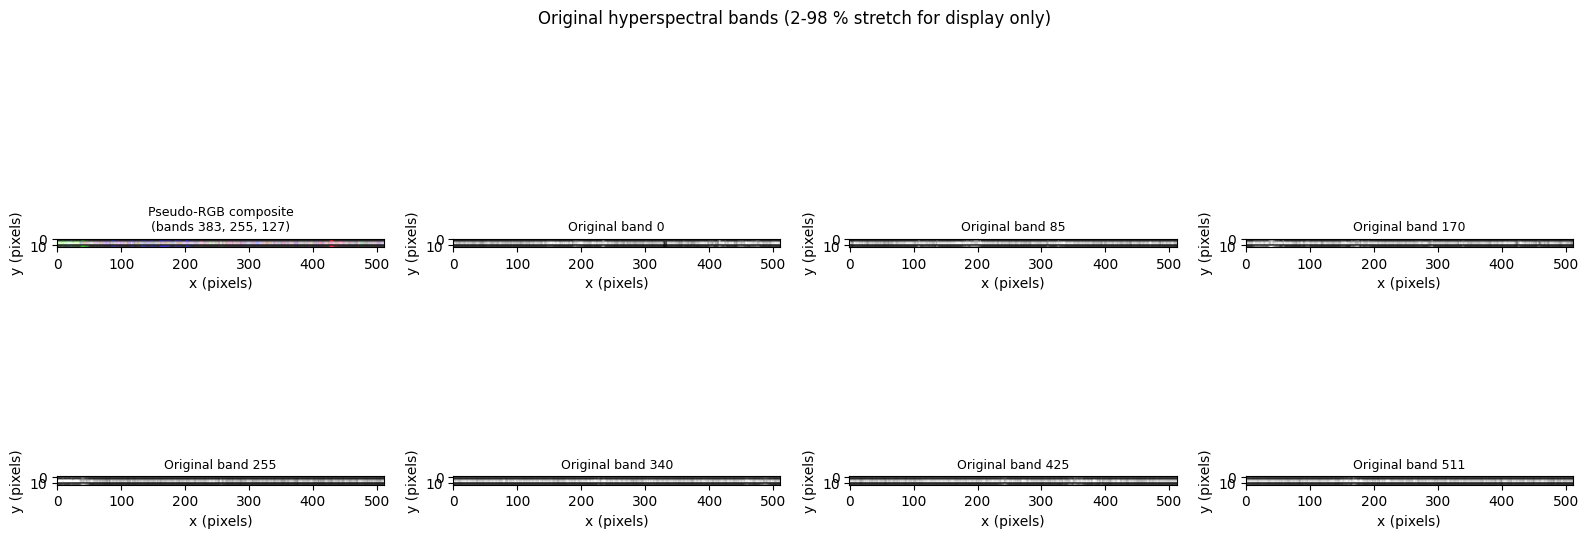

Pseudo-RGB rule: no usable wavelengths: valid bands at 75%/50%/25% of the index range used as R/G/B (false colour, visualisation only)


In [19]:
# ---------- exploratory figure 1: original image with a documented band-combination strategy ----------
def stretch(x, lo=2, hi=98):
    a, b = np.percentile(x[MASK], [lo, hi]); return np.clip((x - a) / (b - a + 1e-12), 0, 1)

def pseudo_rgb_bands():
    if WL_ORIG is not None:
        wl = WL_ORIG[VALID_IDX]; scale = 1000.0 if wl.max() < 10 else 1.0     # micrometres -> nm
        if (wl * scale).min() < 700 and (wl * scale).max() > 600:
            pos = [int(np.argmin(np.abs(wl * scale - t))) for t in (650, 550, 470)]
            return pos, "nearest valid bands to 650/550/470 nm (R/G/B)"
    return [int(0.75 * (B_V - 1)), int(0.5 * (B_V - 1)), int(0.25 * (B_V - 1))], \
           "no usable wavelengths: valid bands at 75%/50%/25% of the index range used as R/G/B (false colour, visualisation only)"

pos_rgb, rgb_note = pseudo_rgb_bands()
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
ax[0, 0].imshow(np.dstack([stretch(XB[VALID_IDX[p]]) for p in pos_rgb]))
ax[0, 0].set_title("Pseudo-RGB composite\n(bands " + ", ".join(str(VALID_IDX[p]) for p in pos_rgb) + ")", fontsize=9)
for a, p in zip(ax.ravel()[1:], np.linspace(0, B_V - 1, 7).astype(int)):
    a.imshow(stretch(XB[VALID_IDX[p]]), cmap="gray"); a.set_title(f"Original band {VALID_IDX[p]}", fontsize=9)
for a in ax.ravel(): a.set_xlabel("x (pixels)"); a.set_ylabel("y (pixels)"); a.grid(False)
plt.suptitle("Original hyperspectral bands (2-98 % stretch for display only)")
plt.tight_layout(); savefig("01_original_band_examples"); plt.show()
print("Pseudo-RGB rule:", rgb_note)

## Section 9 — Band feature representation

**What:** view the cube as a matrix with **one row per original band**.
**Transformation:** $H\times W\times B \to B\times(H\cdot W)$: band $b$ is flattened into a vector $x_b\in\mathbb{R}^{HW}$. The array `FLAT = XB.reshape(B, H*W)` is a *view* (no copy). Row $b$ is original band $b$; restricting to valid pixels gives the $N$ values used by **both** methods.

**Sampling.** Variance and entropy use **all** valid pixels (no sampling), so their scores are exact. A reproducible random sample of `n_sample_pixels` valid pixels is used **only** for the *redundancy evaluation metric* (pairwise Pearson correlation of bands), which would otherwise need a $B\times HW$ matrix product. Sampling affects only that metric.

**What this cell does:** creates the band-by-pixel matrix view and a small sampled correlation matrix.  
**Why it is needed:** both models read bands the same way; the correlation matrix is needed later for the redundancy metric.  
**How it works:** `reshape` gives a no-copy view; correlation = dot product of zero-mean, unit-norm band vectors on sampled pixels.  
**Expected output:** matrix shape, number of valid pixels and the mean absolute correlation of all valid band pairs (a reference level for redundancy).

In [20]:
FLAT = XB.reshape(B_TOTAL, -1)                                  # (B, H*W) view; row b = original band b
VALID_PIX = np.flatnonzero(MASK.ravel())                        # flat indices of valid pixels
print(f"Band matrix FLAT: {FLAT.shape} (rows = ORIGINAL bands, columns = pixels) | valid pixels per band: {VALID_PIX.size}")

def band_values(b_orig):
    # all valid pixel values of one ORIGINAL band as float64 (same pixels for every band and both methods)
    return XB[b_orig][MASK].astype(np.float64)

# --- sampled correlation matrix, used ONLY for the redundancy evaluation metric ---
rng = np.random.default_rng(CONFIG["seed"])
n_s = min(CONFIG["n_sample_pixels"], VALID_PIX.size)
SAMPLE_PIX = np.sort(rng.choice(VALID_PIX, size=n_s, replace=False))
Zs = FLAT[np.ix_(VALID_IDX, SAMPLE_PIX)].astype(np.float64)
Zs -= Zs.mean(axis=1, keepdims=True)
nrm = np.linalg.norm(Zs, axis=1, keepdims=True); assert (nrm > 0).all(), "a valid band is constant on the sampled pixels; increase n_sample_pixels"
Zs /= nrm
R = np.clip(Zs @ Zs.T, -1.0, 1.0)                               # Pearson correlation between valid bands
del Zs
assert np.isfinite(R).all() and np.allclose(np.diag(R), 1.0, atol=1e-9)
off = R[~np.eye(B_V, dtype=bool)]
print(f"Correlation matrix R ({R.shape}) from {n_s} sampled pixels (evaluation metric only). Off-diagonal mean |r| over ALL valid bands = {np.abs(off).mean():.4f}")

Band matrix FLAT: (512, 6656) (rows = ORIGINAL bands, columns = pixels) | valid pixels per band: 6656
Correlation matrix R ((512, 512)) from 6656 sampled pixels (evaluation metric only). Off-diagonal mean |r| over ALL valid bands = 0.9476


## Section 10 — Configuration of Top-K values

**What:** turn the retention percentages (or an explicit `K_list`) into valid integer Top-$K$ values.
**Rule:** $K=\max(1,\operatorname{round}(p/100\cdot B))$ with $B$ = **original total** number of bands, then keep only $1\le K<B_v$ and remove duplicates. The *same* `K_LIST` is used by both models. Retention percentage is always reported as $100\,K/B$.
The example values 5/10/15/20/25 are only defaults; the real numbers depend on this dataset's band count.

**What this cell does:** converts retention percentages into integer Top-K values valid for this dataset.  
**Why it is needed:** both models must use exactly the same K values, and K cannot exceed the number of rankable bands.  
**How it works:** rounds percent × B, enforces 1 ≤ K < B_v, removes duplicates; creates containers for results.  
**Expected output:** the K list, matching retention percentages and the reference K.

In [21]:
def resolve_K_list():
    if CONFIG["K_list"]:
        ks = [int(k) for k in CONFIG["K_list"]]
    else:
        ks = [max(1, int(round(p / 100 * B_TOTAL))) for p in CONFIG["retention_percent"]]
    ok = sorted({k for k in ks if 1 <= k < B_V}); dropped = sorted(set(ks) - set(ok))
    if dropped: print(f"Dropped invalid K values (need 1 <= K < B_v = {B_V}): {dropped}")
    assert ok, "no valid K could be formed for this dataset - check CONFIG['retention_percent'] / ['K_list']"
    return ok

K_LIST = resolve_K_list()
K_REF = K_LIST[len(K_LIST) // 2]
print(f"B (original) = {B_TOTAL} | B_v (rankable) = {B_V}")
print("Top-K values used by BOTH models:", K_LIST, "| retention % of original B:", [round(100 * k / B_TOTAL, 2) for k in K_LIST])
print("Reference K for single-K figures:", K_REF)
METHODS = ["Variance", "Entropy"]
SC, RANKING, RANKPOS, SEL, TIMES = {}, {}, {}, {m: {} for m in METHODS}, {}

B (original) = 512 | B_v (rankable) = 512
Top-K values used by BOTH models: [26, 51, 77, 102, 128] | retention % of original B: [5.08, 9.96, 15.04, 19.92, 25.0]
Reference K for single-K figures: 77


## Section 11 — Variance-based ranking methodology (Model A)

For valid band $b$ with valid pixel values $x_{b,1},\dots,x_{b,N}$:
$$\mu_b=\frac1N\sum_{i=1}^{N}x_{b,i},\qquad \operatorname{Var}_b=\frac1N\sum_{i=1}^{N}(x_{b,i}-\mu_b)^2 .$$
**Convention: population variance** (divide by $N$, `ddof=0`). Sample variance ($N-1$) would multiply all scores by the same factor $N/(N-1)$ and cannot change the ranking, because $N$ is identical for every band here. Raw values are used (no normalisation, Section 7). All valid pixels are used; scores are accumulated in `float64`.

**Ranking:** sort descending (highest variance = rank 1; ties broken by the lower original band index, deterministic). **Top-K:** the first $K$ rows of the ranking. The selected bands are actual original bands.

**Meaning:** high variance = values vary a lot across pixels = potentially more contrast. **Caveat:** noise raises variance too, and neighbouring high-variance bands are usually highly correlated.

## Section 12 — Variance score calculation

**What this cell does:** calculates the population variance of every valid band over all valid pixels.  
**Why it is needed:** this is the score that Model A ranks by.  
**How it works:** for each band: take its valid pixel values, compute the mean, then the mean of squared deviations; compare with `np.var` on five bands as a self-check.  
**Expected output:** one variance per valid band and its min/median/max, plus the computation time.

In [22]:
def variance_scores():
    v = np.zeros(B_V); m = np.zeros(B_V); n = np.zeros(B_V, dtype=np.int64)
    for i, b in enumerate(VALID_IDX):
        x = band_values(b)
        n[i] = x.size; m[i] = x.mean(); v[i] = np.mean((x - m[i]) ** 2)      # population variance (ddof = 0)
    return v, m, n

t0 = time.perf_counter(); VAR, VAR_MEAN, VAR_N = variance_scores(); t_var_score = time.perf_counter() - t0
SC["Variance"] = VAR
# correctness checks against NumPy's own implementation on a few bands
for i in np.linspace(0, B_V - 1, min(5, B_V)).astype(int):
    assert np.isclose(VAR[i], np.var(band_values(VALID_IDX[i]), ddof=0), rtol=1e-9), "variance mismatch"
assert np.isfinite(VAR).all() and (VAR > 0).all() and (VAR_N == N_VALID_PIX).all()
print(f"Variance computed for {B_V} valid bands (population variance, N = {N_VALID_PIX} valid pixels each) in {t_var_score:.3f} s")
print(f"variance: min {VAR.min():.6g} | median {np.median(VAR):.6g} | max {VAR.max():.6g}")

Variance computed for 512 valid bands (population variance, N = 6656 valid pixels each) in 0.034 s
variance: min 922103 | median 1.00918e+06 | max 1.29956e+06


## Section 13 — Variance ranking and Top-K selection

**What this cell does:** sorts the bands by variance (largest first) and takes the first K for every K in the list.  
**Why it is needed:** this is the actual band selection of Model A.  
**How it works:** `lexsort` gives a deterministic descending order; the first K valid positions are mapped back to original band indices.  
**Expected output:** the top of the ranking table and the selected original bands for every K.

In [23]:
def rank_desc(scores):
    # descending order; ties -> lower valid-band position first (deterministic)
    order = np.lexsort((np.arange(len(scores)), -scores))
    pos = np.empty(len(scores), dtype=int); pos[order] = np.arange(1, len(scores) + 1)
    return order, pos

def build_ranking(method, scores, extra):
    t0 = time.perf_counter(); order, pos = rank_desc(scores); t_rank = time.perf_counter() - t0
    sel = {K: order[:K].copy() for K in K_LIST}                      # valid positions, in rank order
    for K, s in sel.items():
        assert len(set(s.tolist())) == K, "duplicate band selected"
    df = pd.DataFrame({"rank": np.arange(1, B_V + 1), "original_band_0based": VALID_IDX[order], "original_band_1based": VALID_IDX[order] + 1,
                       "score": scores[order]})
    for k, v in extra.items(): df[k] = v[order]
    return order, pos, sel, df, t_rank

ord_v, RANKPOS["Variance"], SEL["Variance"], RANKING["Variance"], t_var_rank = build_ranking(
    "Variance", VAR, {"mean": VAR_MEAN, "n_valid_pixels": VAR_N})
RANKING["Variance"] = RANKING["Variance"].rename(columns={"score": "variance_population"})
TIMES["Variance"] = dict(score_s=t_var_score, rank_s=t_var_rank)
print("Top 10 of the variance ranking:"); print(RANKING["Variance"].head(10).to_string(index=False))
for K in K_LIST:
    print(f"  K={K:>3} ({100*K/B_TOTAL:5.2f} % of B): original bands (0-based, rank order) = {VALID_IDX[SEL['Variance'][K]].tolist()}")

Top 10 of the variance ranking:
 rank  original_band_0based  original_band_1based  variance_population        mean  n_valid_pixels
    1                   240                   241         1.299563e+06 2394.730919            6656
    2                   231                   232         1.297827e+06 2387.771334            6656
    3                   232                   233         1.292316e+06 2388.850811            6656
    4                   241                   242         1.292306e+06 2390.940505            6656
    5                   244                   245         1.291312e+06 2381.414062            6656
    6                   235                   236         1.290924e+06 2399.604267            6656
    7                   228                   229         1.289900e+06 2388.304537            6656
    8                   236                   237         1.288886e+06 2401.243840            6656
    9                   229                   230         1.285678e+06 2388.3

## Section 14 — Variance-based selected-band outputs

Saved for every $K$: the complete ranking (CSV), the selected band indices with their rank positions (CSV, 0- and 1-based), the number and percentage of retained bands, and the **reduced cube $H\times W\times K$** (`.npy`, `float32`; channels are in **ascending original band order**, the CSV lists the matching indices). Selected bands are exact copies of original bands; pixels flagged invalid (if any) were set to 0.

**What this cell does:** writes the variance ranking, selected-band tables and reduced cubes to disk.  
**Why it is needed:** the deliverables must be exported and the reduced H × W × K cube must contain genuine original bands.  
**How it works:** slices the selected bands out of the cube (sorted by original index), asserts shape and equality with the originals, saves CSV and `.npy`.  
**Expected output:** a confirmation line; files appear in `rankings/`, `selected_bands/` and `reduced_cubes/`.

In [24]:
def export_method(method):
    tag = method.lower()
    RANKING[method].to_csv(RANK_DIR / f"{tag}_ranking_all_bands.csv", index=False)
    for K in K_LIST:
        sel = SEL[method][K]; orig = VALID_IDX[sel]
        pd.DataFrame({"rank": np.arange(1, K + 1), "original_band_0based": orig, "original_band_1based": orig + 1,
                      "score": SC[method][sel], "retained_bands": K, "retention_percent": 100 * K / B_TOTAL}
                     ).to_csv(SELB_DIR / f"{tag}_top{K}_selected_bands.csv", index=False)
        if CONFIG["export_cubes"] == "all" or (CONFIG["export_cubes"] == "ref" and K == K_REF):
            srt = np.sort(orig); cube = np.moveaxis(XB[srt], 0, 2)
            assert cube.shape == (H, W, K), cube.shape
            assert np.array_equal(cube[..., 0], XB[srt[0]]) and np.array_equal(cube[..., -1], XB[srt[-1]]), "reduced cube is not made of original bands"
            np.save(CUBE_DIR / f"{tag}_K{K}_reduced_cube_HWK.npy", cube)
    print(f"{method}: ranking + {len(K_LIST)} selected-band tables saved; reduced cubes: {CONFIG['export_cubes']}  (shape H x W x K, e.g. {(H, W, K_LIST[0])})")

def show_selected(method, K, name):
    sel = SEL[method][K]; ncol = min(K, 5); nrow = math.ceil(K / ncol)
    fig, ax = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 3.0 * nrow), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for j, p in enumerate(sel):
        ax[j // ncol, j % ncol].imshow(stretch(XB[VALID_IDX[p]]), cmap="gray")
        ax[j // ncol, j % ncol].set_title(f"rank {j+1}: band {VALID_IDX[p]}\n{method.lower()} = {SC[method][p]:.4g}", fontsize=8)
    plt.suptitle(f"{method}-based ranking: selected bands, K = {K} (2-98 % display stretch)")
    plt.tight_layout(); savefig(name); plt.show()

export_method("Variance")

Variance: ranking + 5 selected-band tables saved; reduced cubes: all  (shape H x W x K, e.g. (13, 512, 26))


## Section 15 — Variance visualizations

**How to read them:** (1) *Bar chart*: one bar per band along the spectrum; highlighted bars are the Top-$K_{ref}$ bands. (2) *Ranked plot*: scores sorted from rank 1 downward; dashed lines mark each tested $K$ — a steep drop means the first few bands are much "stronger" than the rest. (3) *Band-index plot*: how the score changes along the spectrum. (4) *Selected band images*: what the chosen bands look like.

**What this cell does:** draws the variance bar chart, the ranked-score curve, variance vs. band index, and the images of the selected bands.  
**Why it is needed:** visual inspection shows where the high-variance bands lie and whether they bunch together.  
**How it works:** Matplotlib plots using the scores and the Top-K selection for the reference K.  
**Expected output:** two figures (saved as PNG) and a one-line interpretation hint.

saved: /kaggle/working/hsi_ranking_outputs/figures/15a_variance_score_plots.png


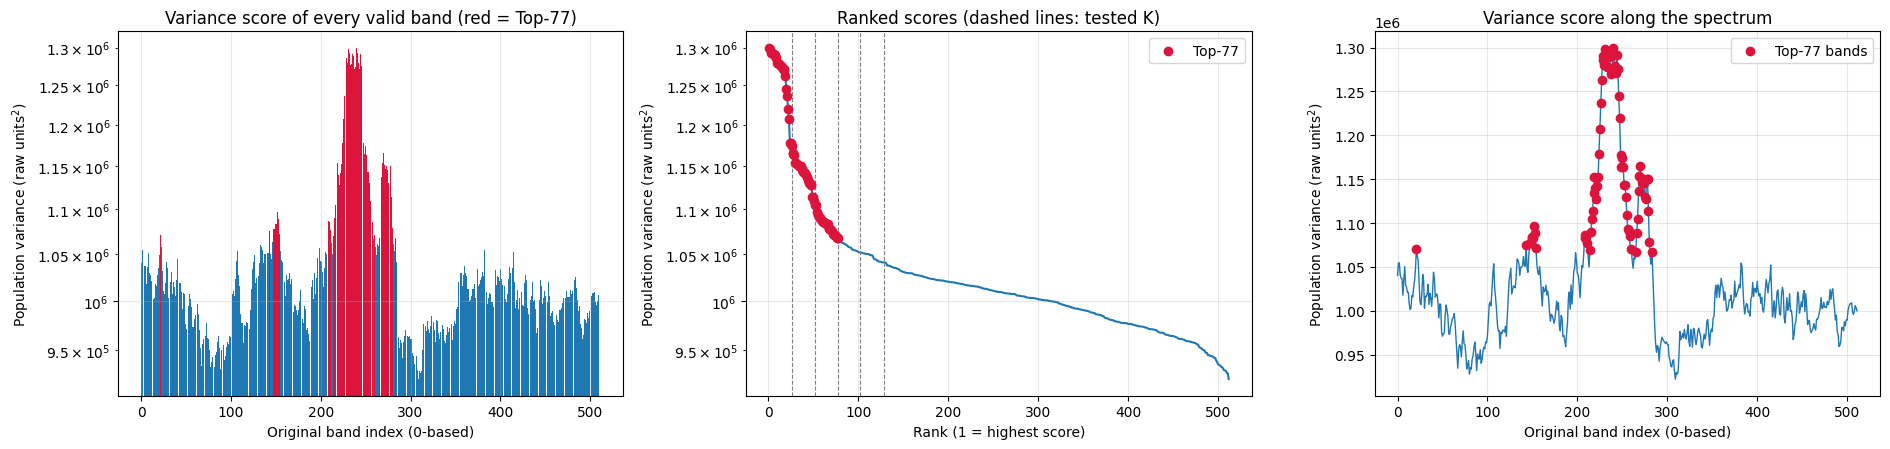

saved: /kaggle/working/hsi_ranking_outputs/figures/15b_variance_selected_bands.png


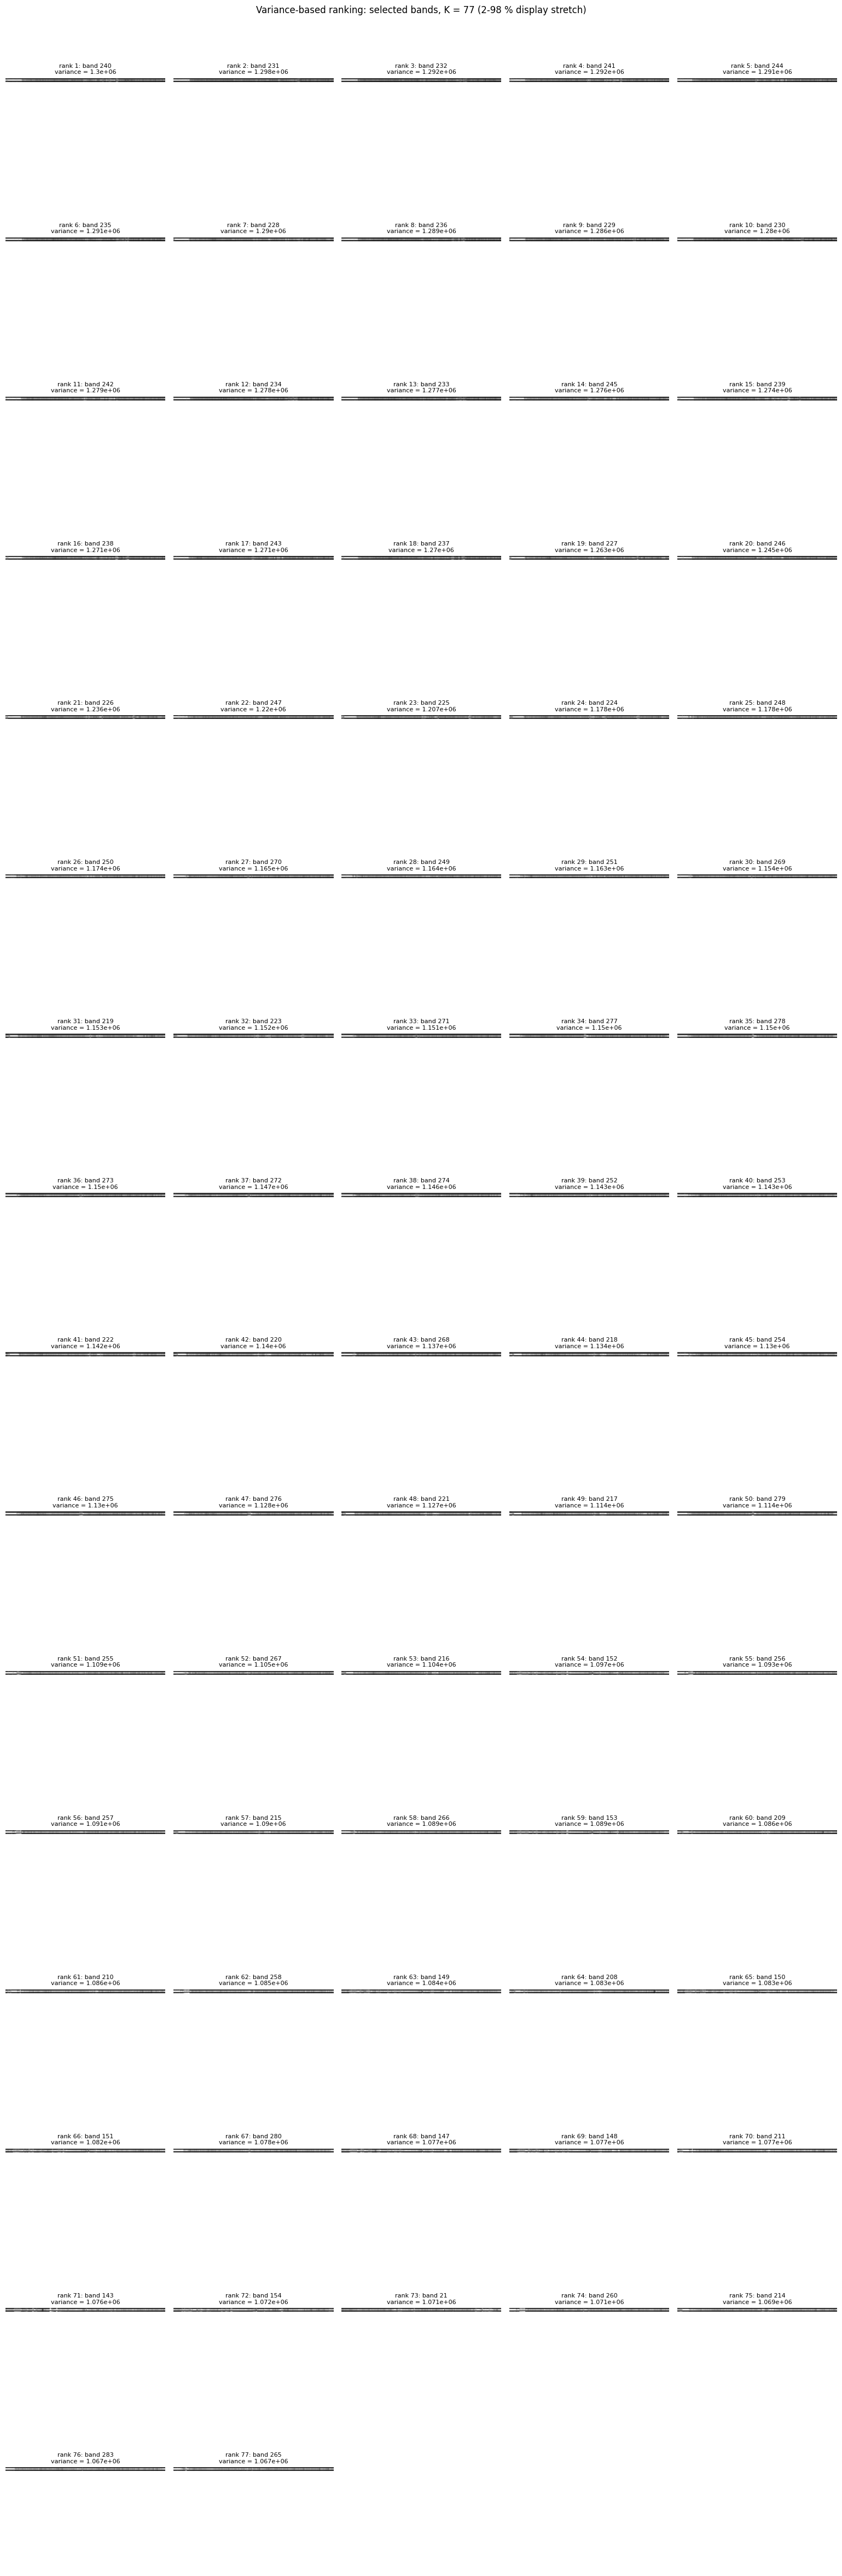

Interpretation: contiguous groups of red bars/points mean the Top-K bands cluster in one spectral region (a typical weakness of single-band ranking).


In [25]:
XL = WL_ORIG[VALID_IDX] if WL_ORIG is not None else VALID_IDX
XLABEL = "Wavelength (dataset units)" if WL_ORIG is not None else "Original band index (0-based)"
COLORS = {"Variance": "tab:blue", "Entropy": "tab:orange"}

def score_figures(method, ylabel, prefix, log_y=False):
    s = SC[method]; sel = SEL[method][K_REF]; c = COLORS[method]
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
    colors = np.where(np.isin(np.arange(B_V), sel), "crimson", c)
    ax[0].bar(VALID_IDX, s, color=colors, width=0.9); ax[0].set_xlabel("Original band index (0-based)"); ax[0].set_ylabel(ylabel)
    ax[0].set_title(f"{method} score of every valid band (red = Top-{K_REF})")
    if log_y: ax[0].set_yscale("log")
    srt = np.sort(s)[::-1]; ax[1].plot(np.arange(1, B_V + 1), srt, color=c)
    for K in K_LIST: ax[1].axvline(K + 0.5, color="gray", ls="--", lw=0.8)
    ax[1].scatter(np.arange(1, K_REF + 1), srt[:K_REF], color="crimson", zorder=3, label=f"Top-{K_REF}")
    ax[1].set_xlabel("Rank (1 = highest score)"); ax[1].set_ylabel(ylabel); ax[1].set_title("Ranked scores (dashed lines: tested K)"); ax[1].legend()
    if log_y: ax[1].set_yscale("log")
    ax[2].plot(XL, s, color=c, lw=1); ax[2].scatter(XL[sel], s[sel], color="crimson", zorder=3, label=f"Top-{K_REF} bands")
    ax[2].set_xlabel(XLABEL); ax[2].set_ylabel(ylabel); ax[2].set_title(f"{method} score along the spectrum"); ax[2].legend()
    plt.tight_layout(); savefig(prefix); plt.show()

score_figures("Variance", "Population variance (raw units$^2$)", "15a_variance_score_plots", log_y=True)
show_selected("Variance", K_REF, "15b_variance_selected_bands")
print("Interpretation: contiguous groups of red bars/points mean the Top-K bands cluster in one spectral region (a typical weakness of single-band ranking).")

## Section 16 — Entropy-based ranking methodology (Model B)

For each valid band we estimate a discrete distribution with a histogram and compute Shannon entropy
$$H_b=-\sum_{i=1}^{M}p_{b,i}\log_2 p_{b,i}\quad[\text{bits}],\qquad p_{b,i}=\frac{n_{b,i}}{N},\quad \sum_i p_{b,i}=1,$$
where $n_{b,i}$ = number of valid pixels of band $b$ in bin $i$ and $0\log 0:=0$ (only non-empty bins enter the sum). **Entropy measures the uncertainty (information content) of the pixel-value distribution:** if all pixels fall into one bin $H=0$; if they spread evenly over $M$ bins $H=\log_2M$ (the maximum).

**Histogram strategy (our engineering decision):** the **same $M$ bins** and the **same bin edges** for every band: $M$ equal-width bins between the global minimum and global maximum of all valid bands over valid pixels. Probabilities are **probability masses** (counts divided by total valid count), *not* density values. This makes entropies of different bands comparable.
**Effect of bin count:** few bins → coarse, low entropies and many ties; many bins → higher entropies; with $M$ larger than the number of distinct intensity levels the estimate saturates. Section 18 measures how stable the *ranking* is with respect to $M$.
Model B never uses the variance scores.

## Section 17 — Histogram-based probability estimation

**What this cell does:** defines the common histogram bins, the probability-mass function of a band and the entropy formula, and tests them on cases with known answers.  
**Why it is needed:** entropies are only comparable if every band uses identical bins and the probabilities are true masses that sum to 1.  
**How it works:** `np.linspace` makes shared bin edges from the global valid range; counts are divided by the total count; empty bins are skipped in the sum.  
**Expected output:** a confirmation of three analytic tests and the printed histogram configuration (bins, range, bin width, log base).

In [26]:
ENT_LO = float(stats.loc[VALID_IDX, "min"].min()); ENT_HI = float(stats.loc[VALID_IDX, "max"].max())

def make_edges(bins):
    return np.linspace(ENT_LO, ENT_HI, bins + 1)           # common bin edges for ALL bands

def band_pmf(b_orig, edges):
    x = XB[b_orig][MASK]
    counts, _ = np.histogram(x, bins=edges)
    assert counts.sum() == x.size, "values fell outside the common histogram range"
    return counts / counts.sum(), x.size                  # probability MASS (sums to 1), not a density

def entropy_from_pmf(p):
    nz = p > 0                                            # 0*log(0) := 0
    return float(-(p[nz] * np.log2(p[nz])).sum())

# --- unit tests of the entropy function (known analytic answers) ---
assert entropy_from_pmf(np.array([1.0, 0, 0, 0])) == 0.0
assert np.isclose(entropy_from_pmf(np.array([0.5, 0.5, 0, 0])), 1.0)
assert np.isclose(entropy_from_pmf(np.full(8, 1 / 8)), 3.0)
_p, _n = band_pmf(VALID_IDX[0], make_edges(CONFIG["entropy_bins"]))
assert np.isclose(_p.sum(), 1.0) and _n == N_VALID_PIX
print("Entropy unit tests passed (constant -> 0 bits, two equal bins -> 1 bit, uniform over 8 bins -> 3 bits).")
print(f"Histogram configuration: {CONFIG['entropy_bins']} equal-width bins | common range [{ENT_LO:.6g}, {ENT_HI:.6g}] "
      f"| bin width {(ENT_HI-ENT_LO)/CONFIG['entropy_bins']:.6g} | log base 2 | upper bound log2(bins) = {math.log2(CONFIG['entropy_bins']):.3f} bits")
print(f"Stored raw dtype {ORIG_DTYPE}: at most {2**ORIG_BITS if ORIG_DTYPE.kind in 'ui' else 'many'} distinct integer levels exist; if that is smaller than the bin count, some bins are always empty.")

Entropy unit tests passed (constant -> 0 bits, two equal bins -> 1 bit, uniform over 8 bins -> 3 bits).
Histogram configuration: 256 equal-width bins | common range [1007, 7206] | bin width 24.2148 | log base 2 | upper bound log2(bins) = 8.000 bits
Stored raw dtype uint16: at most 65536 distinct integer levels exist; if that is smaller than the bin count, some bins are always empty.


## Section 18 — Shannon entropy calculation

Besides the main run (`entropy_bins`), a **diagnostic** recomputes the scores with other bin counts and reports (i) the Spearman rank correlation with the main ranking and (ii) how many of the reference Top-$K$ bands stay the same. This diagnostic does **not** change the selection.

**What this cell does:** calculates Shannon entropy for every valid band and tests how sensitive the ranking is to the number of bins.  
**Why it is needed:** this is the score Model B ranks by; the diagnostic shows whether the chosen bin count matters.  
**How it works:** histogram with common edges → probabilities → entropy per band; extra runs with other bin counts are compared by Spearman correlation and Top-K overlap.  
**Expected output:** min/median/max entropy, timing, and a small sensitivity table (saved as CSV).

In [27]:
def entropy_scores(bins):
    edges = make_edges(bins); e = np.zeros(B_V); n = np.zeros(B_V, dtype=np.int64)
    for i, b in enumerate(VALID_IDX):
        p, n[i] = band_pmf(b, edges); e[i] = entropy_from_pmf(p)
    return e, n

t0 = time.perf_counter(); ENT, ENT_N = entropy_scores(CONFIG["entropy_bins"]); t_ent_score = time.perf_counter() - t0
SC["Entropy"] = ENT
assert np.isfinite(ENT).all() and (ENT >= 0).all() and (ENT <= math.log2(CONFIG["entropy_bins"]) + 1e-9).all() and (ENT_N == N_VALID_PIX).all()
print(f"Entropy computed for {B_V} valid bands ({CONFIG['entropy_bins']} common bins) in {t_ent_score:.3f} s")
print(f"entropy (bits): min {ENT.min():.4f} | median {np.median(ENT):.4f} | max {ENT.max():.4f}")

sens_rows = []
if CONFIG["entropy_bin_sensitivity"]:
    ref_order = np.lexsort((np.arange(B_V), -ENT))
    for nb in CONFIG["entropy_bin_sensitivity"]:
        e2, _ = entropy_scores(nb); o2 = np.lexsort((np.arange(B_V), -e2))
        sens_rows.append(dict(bins=nb, spearman_rho_vs_main=float(spearmanr(ENT, e2)[0]),
                              **{f"top{K}_overlap": len(set(ref_order[:K]) & set(o2[:K])) for K in K_LIST}))
    SENS = pd.DataFrame(sens_rows); SENS.to_csv(TAB_DIR / "entropy_bin_sensitivity.csv", index=False)
    print(f"\nSensitivity of the entropy RANKING to the bin count (main = {CONFIG['entropy_bins']} bins); topK_overlap = number of shared selected bands:")
    print(SENS.round(4).to_string(index=False))

Entropy computed for 512 valid bands (256 common bins) in 0.082 s
entropy (bits): min 5.8913 | median 6.1422 | max 6.4048

Sensitivity of the entropy RANKING to the bin count (main = 256 bins); topK_overlap = number of shared selected bands:
 bins  spearman_rho_vs_main  top26_overlap  top51_overlap  top77_overlap  top102_overlap  top128_overlap
   32                0.9056              8             23             40              63              90
   64                0.9759             21             42             69              92             120
  128                0.9902             25             43             72              96             124
  512                0.9946             24             47             72              97             121


## Section 19 — Entropy ranking and Top-K selection

**What this cell does:** sorts the bands by entropy (largest first) and selects Top-K for the same K values as Model A.  
**Why it is needed:** this is the actual band selection of Model B, computed independently of Model A.  
**How it works:** same sorting routine as before; the table also stores the histogram configuration (bins, range, log base) and valid pixel count.  
**Expected output:** the top of the entropy ranking and the selected original bands for every K.

In [28]:
ord_e, RANKPOS["Entropy"], SEL["Entropy"], RANKING["Entropy"], t_ent_rank = build_ranking(
    "Entropy", ENT, {"n_valid_pixels": ENT_N})
RANKING["Entropy"] = RANKING["Entropy"].rename(columns={"score": "entropy_bits"})
RANKING["Entropy"]["n_bins"] = CONFIG["entropy_bins"]; RANKING["Entropy"]["range_low"] = ENT_LO
RANKING["Entropy"]["range_high"] = ENT_HI; RANKING["Entropy"]["log_base"] = 2
TIMES["Entropy"] = dict(score_s=t_ent_score, rank_s=t_ent_rank)
print("Top 10 of the entropy ranking:"); print(RANKING["Entropy"].head(10).to_string(index=False))
for K in K_LIST:
    print(f"  K={K:>3} ({100*K/B_TOTAL:5.2f} % of B): original bands (0-based, rank order) = {VALID_IDX[SEL['Entropy'][K]].tolist()}")

Top 10 of the entropy ranking:
 rank  original_band_0based  original_band_1based  entropy_bits  n_valid_pixels  n_bins  range_low  range_high  log_base
    1                   140                   141      6.404753            6656     256     1007.0      7206.0         2
    2                   139                   140      6.400398            6656     256     1007.0      7206.0         2
    3                   157                   158      6.388817            6656     256     1007.0      7206.0         2
    4                   154                   155      6.387777            6656     256     1007.0      7206.0         2
    5                   135                   136      6.387661            6656     256     1007.0      7206.0         2
    6                   239                   240      6.386723            6656     256     1007.0      7206.0         2
    7                   108                   109      6.386292            6656     256     1007.0      7206.0         2
 

## Section 20 — Entropy-based selected-band outputs

**What this cell does:** writes the entropy ranking, selected-band tables and reduced cubes to disk.  
**Why it is needed:** same deliverables as Model A, in the same format.  
**How it works:** re-uses `export_method` from Section 14.  
**Expected output:** a confirmation line; new files in `rankings/`, `selected_bands/`, `reduced_cubes/`.

In [29]:
export_method("Entropy")

Entropy: ranking + 5 selected-band tables saved; reduced cubes: all  (shape H x W x K, e.g. (13, 512, 26))


## Section 21 — Entropy visualizations

**How to read them:** the score plots work like in Section 15. The **score distribution** shows how spread out the entropies are (if almost all bands are close to the maximum, entropy discriminates poorly). The **probability-mass examples** show the histogram behind the number: a broad, flat histogram = high entropy; a narrow spike = low entropy.

**What this cell does:** draws the entropy bar/ranked/index plots, the selected band images, the distribution of entropy scores and example probability-mass curves.  
**Why it is needed:** to see where high-entropy bands lie and what a high/low entropy histogram actually looks like.  
**How it works:** Matplotlib plots re-using the helper functions; example bands are the best, the last selected, and the worst-ranked band.  
**Expected output:** three figures (PNG) and an interpretation hint.

saved: /kaggle/working/hsi_ranking_outputs/figures/21a_entropy_score_plots.png


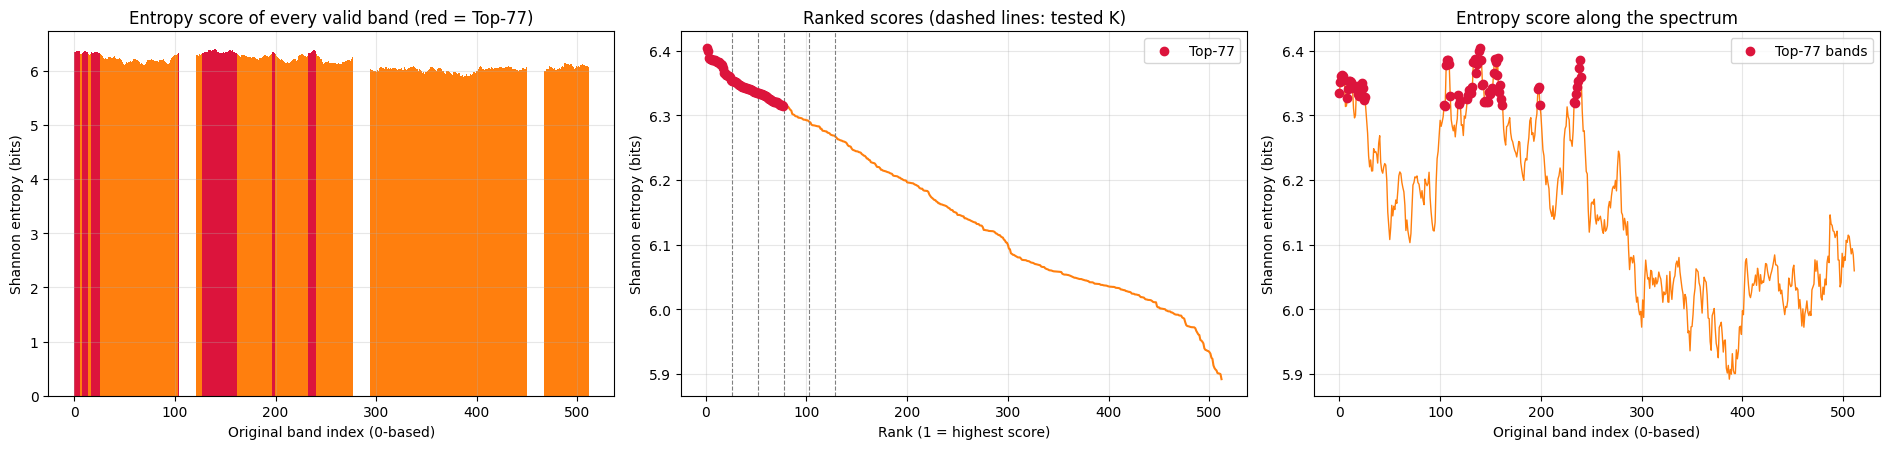

saved: /kaggle/working/hsi_ranking_outputs/figures/21b_entropy_selected_bands.png


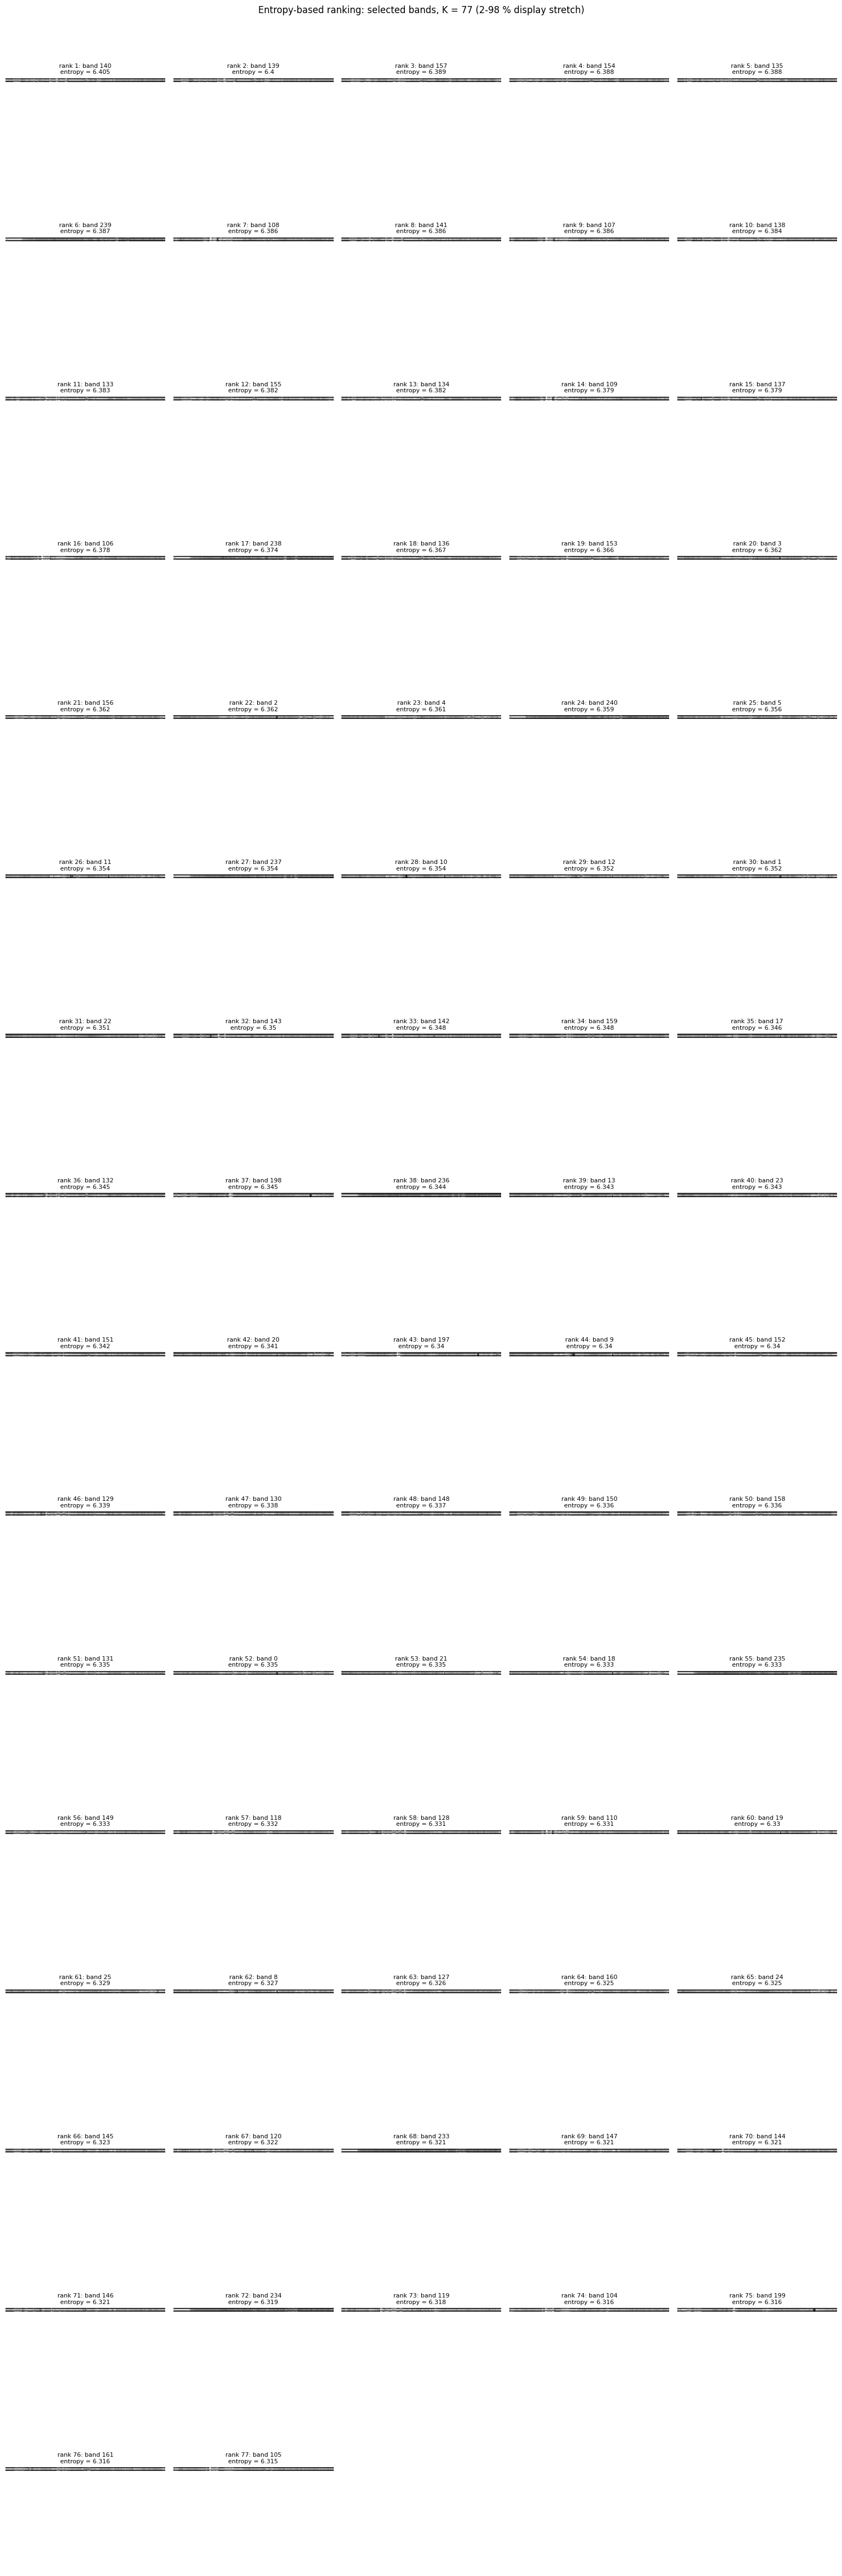

saved: /kaggle/working/hsi_ranking_outputs/figures/21c_entropy_distribution_and_pmf_examples.png


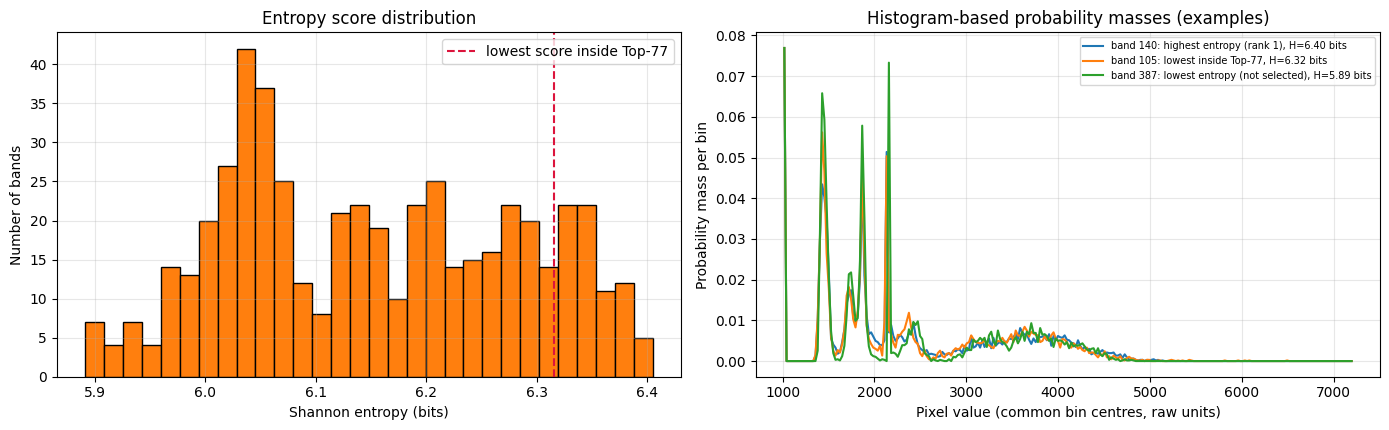

Interpretation: a band whose mass is spread over many bins has high entropy; a spike in a few bins gives low entropy.


In [30]:
score_figures("Entropy", "Shannon entropy (bits)", "21a_entropy_score_plots")
show_selected("Entropy", K_REF, "21b_entropy_selected_bands")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].hist(ENT, bins=min(30, B_V), color=COLORS["Entropy"], edgecolor="k")
ax[0].axvline(ENT[SEL["Entropy"][K_REF]].min(), color="crimson", ls="--", label=f"lowest score inside Top-{K_REF}")
ax[0].set_xlabel("Shannon entropy (bits)"); ax[0].set_ylabel("Number of bands"); ax[0].set_title("Entropy score distribution"); ax[0].legend()
edges = make_edges(CONFIG["entropy_bins"]); centers = 0.5 * (edges[:-1] + edges[1:])
sel_e = SEL["Entropy"][K_REF]; ex = [sel_e[0], sel_e[-1], ord_e[-1]]
labs = [f"band {VALID_IDX[ex[0]]}: highest entropy (rank 1)", f"band {VALID_IDX[ex[1]]}: lowest inside Top-{K_REF}", f"band {VALID_IDX[ex[2]]}: lowest entropy (not selected)"]
for p, l in zip(ex, labs):
    pm, _ = band_pmf(VALID_IDX[p], edges); ax[1].plot(centers, pm, label=f"{l}, H={ENT[p]:.2f} bits")
ax[1].set_xlabel("Pixel value (common bin centres, raw units)"); ax[1].set_ylabel("Probability mass per bin"); ax[1].set_title("Histogram-based probability masses (examples)"); ax[1].legend(fontsize=7)
plt.tight_layout(); savefig("21c_entropy_distribution_and_pmf_examples"); plt.show()
print("Interpretation: a band whose mass is spread over many bins has high entropy; a spike in a few bins gives low entropy.")

## Section 22 — Optional reconstruction evaluation (only if scientifically supported)

Band selection returns $H\times W\times K$. It does **not** recover the other $B_v-K$ bands, and neither ranking performs reconstruction. PSNR, SSIM, SAM, MAE and relative error compare *two full-size cubes*, so they need a **separate, clearly labelled evaluation component** that is identical for both models:

**Linear interpolation along the spectral axis**, using real **wavelengths** as coordinate. For an omitted band at $\lambda$ between neighbouring selected bands $s_l,s_r$:
$$\hat x_\lambda=(1-w)\,x_{s_l}+w\,x_{s_r},\quad w=\tfrac{\lambda-\lambda_{s_l}}{\lambda_{s_r}-\lambda_{s_l}};$$
outside the selected range the nearest selected band is repeated (constant extrapolation). Inputs are only the selected bands; omitted original bands serve only as the reference. No labels, no training, no neural network.
**Gate:** if the dataset has **no usable wavelength information** (and `allow_index_interp=False`) the reconstruction metrics are reported as **N/A** — interpolating over band *index* would silently assume evenly spaced bands.
**Limitation:** linear interpolation ignores absorption features and extrapolates crudely at the ends; Top-K ranked bands are often bunched, which leaves large gaps. These scores therefore reflect *selected-band set + interpolation baseline*, not "reconstruction ability of variance/entropy".

**Metric definitions** (reference $x$, reconstruction $\hat x$, valid pixels, fixed range DR; "omitted" = the $B_v-K$ bands not selected; "full cube" = all valid bands, selected ones having zero error):
* $\mathrm{MSE}$ = mean squared error; $\mathrm{PSNR}=10\log_{10}(\mathrm{DR}^2/\mathrm{MSE})$ dB ($+\infty$ if MSE = 0).
* SSIM: 2-D SSIM per band (uniform window, `data_range=DR`), averaged over bands.
* MAE = mean $|x-\hat x|$ (raw units).
* Mean relative error per band: mean of $|x-\hat x|/|x|$ over pixels with $|x|>\varepsilon$, $\varepsilon$ = `rel_err_eps_frac`×DR. **Zero-denominator policy:** pixels with $|x|\le\varepsilon$ are excluded and the excluded fraction is recorded; aggregate = mean over bands.
* SAM = mean over valid pixels of $\arccos\frac{x\cdot\hat x}{\lVert x\rVert\lVert\hat x\rVert}$ (full spectra over valid bands; zero-norm pixels excluded and counted); radians and degrees, lower is better.

**What this cell does:** decides whether a scientifically justified reconstruction can be built, and defines the interpolation and the five reconstruction metrics.  
**Why it is needed:** PSNR/SSIM/SAM/MAE/relative error need a full-size reconstruction; without wavelengths we refuse to pretend.  
**How it works:** linear interpolation between neighbouring selected bands (constant outside), evaluated band by band so no big array is stored; a self-test checks the metric code on the trivial case 'keep everything'.  
**Expected output:** either 'Reconstruction ENABLED …' plus a passed self-check, or 'N/A' with the reason.

In [31]:
RECON_OK, RECON_REASON, COORD = False, "", None
if not CONFIG["run_reconstruction"]:
    RECON_REASON = "reconstruction disabled in CONFIG"
elif WL_ORIG is not None and np.all(np.diff(WL_ORIG[VALID_IDX]) > 0):
    COORD, RECON_OK, COORD_KIND = WL_ORIG[VALID_IDX].astype(float), True, "wavelength"
elif WL_ORIG is not None and np.all(np.diff(WL_ORIG[VALID_IDX]) < 0):
    COORD, RECON_OK, COORD_KIND = -WL_ORIG[VALID_IDX].astype(float), True, "wavelength (descending, negated)"
elif CONFIG["allow_index_interp"]:
    COORD, RECON_OK, COORD_KIND = VALID_IDX.astype(float), True, "band index (ASSUMES evenly spaced bands)"
else:
    RECON_REASON = "no usable (strictly monotonic) wavelength information in the dataset; interpolation over band index would assume even spacing"
WIN = min(7, H, W); WIN = WIN - 1 if WIN % 2 == 0 else WIN
SSIM_OK = CONFIG["compute_ssim"] and WIN >= 3

def reconstruction_plan(coord, sel_pos):
    sel_pos = np.sort(np.asarray(sel_pos)); sc = coord[sel_pos]; plan = {}
    for p in range(len(coord)):
        c = coord[p]
        if c <= sc[0]:    plan[p] = (sel_pos[0], sel_pos[0], 0.0)
        elif c >= sc[-1]: plan[p] = (sel_pos[-1], sel_pos[-1], 0.0)
        else:
            r = int(np.searchsorted(sc, c, side="right")); l = r - 1
            plan[p] = (sel_pos[l], sel_pos[r], float((c - sc[l]) / (sc[r] - sc[l])))
    return plan

def reconstruct_band(p, plan):
    l, r, w = plan[p]
    return (1.0 - w) * XB[VALID_IDX[l]] + w * XB[VALID_IDX[r]]

def evaluate_reconstruction(sel_pos):
    # streaming evaluation: the reconstructed cube is never stored in memory
    sel_pos = np.sort(np.asarray(sel_pos)); sel_set = set(sel_pos.tolist()); plan = reconstruction_plan(COORD, sel_pos)
    dot = np.zeros((H, W)); nx = np.zeros((H, W)); nr_ = np.zeros((H, W))
    mae_b = np.zeros(B_V); mse_b = np.zeros(B_V); mre_b = np.zeros(B_V); mre_excl = np.zeros(B_V); ssim_b = np.ones(B_V); t_rec = 0.0
    for p in range(B_V):
        x = XB[VALID_IDX[p]].astype(np.float64)
        if p in sel_set:
            r = x
        else:
            t0 = time.perf_counter(); r = reconstruct_band(p, plan).astype(np.float64); t_rec += time.perf_counter() - t0
            e = (x - r)[MASK]; xv = x[MASK]; ok = np.abs(xv) > REL_EPS
            mae_b[p] = np.abs(e).mean(); mse_b[p] = (e ** 2).mean()
            mre_b[p] = (np.abs(e)[ok] / np.abs(xv[ok])).mean() if ok.any() else np.nan
            mre_excl[p] = 1.0 - ok.mean()
            if SSIM_OK: ssim_b[p] = structural_similarity(x, r, data_range=DR, win_size=WIN)
        dot += x * r; nx += x * x; nr_ += r * r
    omit = np.array([p not in sel_set for p in range(B_V)])
    den = np.sqrt(nx * nr_); ok = MASK & (den > 0)
    ang = np.arccos(np.clip(dot[ok] / den[ok], -1.0, 1.0))
    mse_all = mse_b.mean(); mse_om = mse_b[omit].mean()
    psnr = lambda m: float("inf") if m <= 0 else float(10 * np.log10(DR ** 2 / m))
    return dict(PSNR_all=psnr(mse_all), PSNR_omitted=psnr(mse_om),
                SSIM_all=float(ssim_b.mean()) if SSIM_OK else np.nan, SSIM_omitted=float(ssim_b[omit].mean()) if SSIM_OK else np.nan,
                SAM_rad=float(ang.mean()), SAM_deg=float(np.degrees(ang.mean())), SAM_zero_norm_pixels=int((MASK & ~(den > 0)).sum()),
                MAE_all=float(mae_b.mean()), MAE_omitted=float(mae_b[omit].mean()),
                MRE_all=float(np.nanmean(mre_b)), MRE_omitted=float(np.nanmean(mre_b[omit])), MRE_excluded_fraction=float(mre_excl[omit].mean()),
                recon_time_s=t_rec)

if RECON_OK:
    _o = evaluate_reconstruction(np.arange(B_V))          # self-test: keeping all bands must be perfect
    assert _o["MAE_all"] == 0 and _o["SAM_rad"] < 1e-3 and np.isinf(_o["PSNR_all"]), _o
    print(f"Reconstruction ENABLED: linear interpolation over {COORD_KIND}; SSIM window = {WIN}, SSIM on = {SSIM_OK}.")
    print("Self-check passed: keeping all bands gives MAE = 0, PSNR = inf, SAM ~ 0.")
else:
    print("Reconstruction metrics will be reported as N/A.\nReason:", RECON_REASON)

Reconstruction metrics will be reported as N/A.
Reason: no usable (strictly monotonic) wavelength information in the dataset; interpolation over band index would assume even spacing


## Section 23 — Evaluation metrics (storage, retention, redundancy, information, reconstruction)

**Compression ratio.** $\mathrm{CR}=\dfrac{\text{Original bits}}{\text{Compressed bits}}$ with Original bits $=H\,W\,B\,b$ and Compressed bits $=H\,W\,K\,b$ ($b$ = stored bit depth, $B$ = **original total** number of bands). So $\mathrm{CR}=B/K$: **identical for both methods at a given $K$ by construction**. This is *theoretical selected-band storage*, **not** the size of an encoded file, and band indices are not included. An **effective CR** is also given that adds $K\lceil\log_2B\rceil$ bits for the band indices (wavelength metadata is treated as dataset metadata and excluded).
**Bits per pixel.** $\mathrm{bpp}=\dfrac{\text{Compressed bits}}{H\,W\,B}$ (your definition: per *original spectral sample*) and **bits per spatial pixel** $=\dfrac{\text{Compressed bits}}{H\,W}$ (all kept bands of one pixel). They differ by the factor $B$.
**Redundancy.** $\mathrm{Red}=\frac{2}{K(K-1)}\sum_{i<j}|r_{ij}|$ — mean absolute pairwise Pearson correlation of the *selected* bands (sampled pixels). High = the selected bands largely repeat each other; low = more complementary. It does **not** guarantee good classification. *Evaluation only — it never changes a selection.* (N/A for $K=1$.)
**Entropy / information.** Mean Shannon entropy (bits, Section 17 histogram) of the selected bands — reported for **both** models' selections; likewise the mean **variance** of the selected bands. These are *evaluation read-outs*; they do not combine or modify the rankings.
**Selected-band ranking positions.** Rank of each selected band in its own ranking (1…K) and in the *other* method's ranking (shows how much the two rankings disagree).

**What this cell does:** computes, for every method and every K, the storage metrics, retained-band info, redundancy, selected-band entropy/variance and (if enabled) the reconstruction metrics.  
**Why it is needed:** these are the evaluation metrics requested; they are computed identically for both models.  
**How it works:** formulas from the text above; redundancy uses the correlation matrix R from Section 9; reconstruction uses Section 22 (or is left N/A).  
**Expected output:** one printed line per (method, K) and the list of bands chosen by both methods. Everything is stored in the DataFrame `RES`.

In [32]:
def compression_stats(K):
    orig = H * W * B_TOTAL * ORIG_BITS; comp = H * W * K * ORIG_BITS; ovh = K * math.ceil(math.log2(B_TOTAL))
    return dict(original_bits=orig, compressed_bits=comp, CR=orig / comp, overhead_bits=ovh, CR_effective=orig / (comp + ovh),
                bpp=comp / (H * W * B_TOTAL), bits_per_spatial_pixel=comp / (H * W),
                original_MiB=orig / 8 / 2**20, selected_MiB=comp / 8 / 2**20)

ROWS = []
for m in METHODS:
    other = [x for x in METHODS if x != m][0]
    for K in K_LIST:
        sel = SEL[m][K]; orig = VALID_IDX[sel]
        row = dict(method=m, K=K, n_original_bands=B_TOTAL, n_valid_bands=B_V, retention_pct=100 * K / B_TOTAL,
                   selected_0based=json.dumps(orig.tolist()), selected_1based=json.dumps((orig + 1).tolist()),
                   rank_positions_own=json.dumps(list(range(1, K + 1))), rank_positions_in_other_method=json.dumps(RANKPOS[other][sel].tolist()))
        row.update(compression_stats(K))
        row["redundancy"] = float(np.abs(R[np.ix_(sel, sel)])[np.triu_indices(K, 1)].mean()) if K >= 2 else np.nan
        row["mean_selected_entropy"] = float(ENT[sel].mean()); row["mean_selected_variance"] = float(VAR[sel].mean())
        row["min_selected_entropy"] = float(ENT[sel].min())
        if RECON_OK:
            row.update(evaluate_reconstruction(sel))
        ROWS.append(row)
        print(f"  {m:<9} K={K:>3} | CR {row['CR']:.2f} | redundancy {row['redundancy']:.4f} | mean entropy {row['mean_selected_entropy']:.3f} bits"
              + (f" | PSNR_omitted {row['PSNR_omitted']:.2f} dB | SAM {row['SAM_deg']:.3f} deg" if RECON_OK else " | reconstruction metrics N/A"))
RES = pd.DataFrame(ROWS)
for c in ["PSNR_all", "PSNR_omitted", "SSIM_all", "SSIM_omitted", "SAM_rad", "SAM_deg", "SAM_zero_norm_pixels", "MAE_all", "MAE_omitted",
          "MRE_all", "MRE_omitted", "MRE_excluded_fraction", "recon_time_s"]:
    if c not in RES: RES[c] = np.nan
overlap = {K: sorted(set(VALID_IDX[SEL["Variance"][K]]) & set(VALID_IDX[SEL["Entropy"][K]])) for K in K_LIST}
print("\nBands selected by BOTH methods (information only; the methods are not forced to agree):")
for K in K_LIST: print(f"  K={K:>3}: {len(overlap[K])} shared -> {overlap[K]}")

  Variance  K= 26 | CR 19.69 | redundancy 0.9718 | mean entropy 6.280 bits | reconstruction metrics N/A
  Variance  K= 51 | CR 10.04 | redundancy 0.9662 | mean entropy 6.236 bits | reconstruction metrics N/A
  Variance  K= 77 | CR 6.65 | redundancy 0.9511 | mean entropy 6.232 bits | reconstruction metrics N/A
  Variance  K=102 | CR 5.02 | redundancy 0.9407 | mean entropy 6.238 bits | reconstruction metrics N/A
  Variance  K=128 | CR 4.00 | redundancy 0.9341 | mean entropy 6.249 bits | reconstruction metrics N/A
  Entropy   K= 26 | CR 19.69 | redundancy 0.9268 | mean entropy 6.377 bits | reconstruction metrics N/A
  Entropy   K= 51 | CR 10.04 | redundancy 0.9282 | mean entropy 6.361 bits | reconstruction metrics N/A
  Entropy   K= 77 | CR 6.65 | redundancy 0.9274 | mean entropy 6.349 bits | reconstruction metrics N/A
  Entropy   K=102 | CR 5.02 | redundancy 0.9263 | mean entropy 6.337 bits | reconstruction metrics N/A
  Entropy   K=128 | CR 4.00 | redundancy 0.9260 | mean entropy 6.325 

## Section 24 — Downstream classification evaluation (only if labels are available)

Labels are used **only here**. Protocol (identical for both methods, every $K$ and a full-band baseline):
* **Pixels:** valid, labelled (label ≠ background).
* **Spatially separated split (reduces leakage):** the image is divided into square blocks of `split_block` pixels; a fixed random fraction of the blocks goes to *train*, the rest to *test*, so neighbouring pixels never sit on both sides. The split is searched (deterministically, seeded) until every test class also appears in train. If that is impossible, the notebook falls back to a stratified random pixel split and **says so** (that split is optimistic).
* Train/test pixels are capped (`max_train_pixels`, `max_test_pixels`) by one seeded random subsample, then **reused everywhere**. Standardisation is fitted on the training pixels only. Classifier: SVM (RBF, fixed $C$, `gamma="scale"`).
* **OA** = fraction correct; **AA** = mean per-class recall over test classes; **Cohen's κ** $=(p_o-p_e)/(1-p_e)$. A confusion matrix, per-class accuracy and a classification report are stored.
Only one split and one classifier are used, so small differences between the two methods should not be over-interpreted.

**What this cell does:** trains one fixed SVM on the selected bands (for every method and K) and on all bands as a baseline, and computes OA, AA, Kappa, confusion matrices and per-class accuracy.  
**Why it is needed:** this measures downstream usefulness of the selected bands; labels are used here and nowhere else.  
**How it works:** spatial block split → standardise (train only) → RBF-SVM → predictions → metrics; identical settings for every run.  
**Expected output:** the split type and sizes, the full-band baseline and one OA/AA/κ line per (method, K); or N/A with a reason if no labels exist. Reports are saved under `reports/` and `tables/`.

In [33]:
from sklearn.model_selection import train_test_split
CLS, SPLIT_TYPE, CLS_REASON = None, "N/A", ""

def build_split():
    lab_ok = MASK & (LABELS != CONFIG["label_background"])
    if lab_ok.sum() == 0: return None, "N/A", "no labelled valid pixels"
    bs = CONFIG["split_block"]; rr, cc = np.indices((H, W))
    block = ((rr // bs) * math.ceil(W / bs) + (cc // bs)).ravel()
    pix = np.flatnonzero(lab_ok.ravel()); y = LABELS.ravel()[pix]; blk = block[pix]
    ublk = np.unique(blk); rng = np.random.default_rng(CONFIG["seed"])
    split_type, tr, te = None, None, None
    if len(ublk) >= 4:
        for attempt in range(200):
            perm = rng.permutation(ublk); ntr = max(1, int(round(CONFIG["train_block_fraction"] * len(ublk))))
            trb = set(perm[:ntr].tolist()); is_tr = np.array([b in trb for b in blk])
            ctr, cte = set(np.unique(y[is_tr]).tolist()), set(np.unique(y[~is_tr]).tolist())
            if len(cte) >= 2 and cte <= ctr:
                tr, te, split_type = pix[is_tr], pix[~is_tr], f"spatial block split ({bs}x{bs} blocks, attempt {attempt+1})"; ytr, yte = y[is_tr], y[~is_tr]; break
    if split_type is None:
        cls, cnt = np.unique(y, return_counts=True); keep = cls[cnt >= 4]; m_ = np.isin(y, keep)
        if len(keep) < 2: return None, "N/A", "fewer than 2 usable classes"
        tr, te, ytr, yte = train_test_split(pix[m_], y[m_], train_size=0.5, stratify=y[m_], random_state=CONFIG["seed"])
        split_type = "stratified RANDOM pixel split (fallback; optimistic because of spatial autocorrelation)"
    rng2 = np.random.default_rng(CONFIG["seed"] + 1)
    if len(tr) > CONFIG["max_train_pixels"]:
        i = rng2.choice(len(tr), CONFIG["max_train_pixels"], replace=False); tr, ytr = tr[i], ytr[i]
    if len(te) > CONFIG["max_test_pixels"]:
        i = rng2.choice(len(te), CONFIG["max_test_pixels"], replace=False); te, yte = te[i], yte[i]
    assert len(np.intersect1d(tr, te)) == 0, "train/test overlap"
    return dict(tr=tr, te=te, ytr=ytr, yte=yte, classes=np.unique(np.concatenate([ytr, yte]))), split_type, ""

if CONFIG["run_classification"] and LABELS is not None:
    CLS, SPLIT_TYPE, why = build_split()
    if CLS is None: CLS_REASON = why
else:
    CLS_REASON = "no valid pixel-level label map found" if LABELS is None else "classification disabled in CONFIG"

CM, CLS_REPORT, PER_CLASS = {}, {}, []
def classify(cols_orig):
    t0 = time.perf_counter()
    Xtr = FLAT[np.ix_(cols_orig, CLS["tr"])].T.astype(np.float64); Xte = FLAT[np.ix_(cols_orig, CLS["te"])].T.astype(np.float64)
    sc = StandardScaler().fit(Xtr)                                         # fitted on TRAIN only
    clf = SVC(kernel=CONFIG["svm_kernel"], C=CONFIG["svm_C"], gamma="scale", random_state=CONFIG["seed"]).fit(sc.transform(Xtr), CLS["ytr"])
    pred = clf.predict(sc.transform(Xte)); cl = CLS["classes"]
    cm = confusion_matrix(CLS["yte"], pred, labels=cl)
    pc = recall_score(CLS["yte"], pred, labels=cl, average=None, zero_division=0)
    present = np.isin(cl, np.unique(CLS["yte"]))
    res = dict(OA=float(accuracy_score(CLS["yte"], pred)), AA=float(pc[present].mean()), Kappa=float(cohen_kappa_score(CLS["yte"], pred)),
               classif_time_s=time.perf_counter() - t0)
    rep = classification_report(CLS["yte"], pred, labels=cl, zero_division=0)
    return res, cm, rep, pc

BASELINE = None
if CLS is not None:
    print(f"Classification enabled | split: {SPLIT_TYPE}\n  {len(CLS['classes'])} classes | train {len(CLS['tr'])} | test {len(CLS['te'])} pixels (no overlap)")
    pd.DataFrame({"class": CLS["classes"], "train": [(CLS["ytr"] == c).sum() for c in CLS["classes"]],
                  "test": [(CLS["yte"] == c).sum() for c in CLS["classes"]]}).to_csv(TAB_DIR / "classification_split_counts.csv", index=False)
    BASELINE, cm_b, rep_b, pc_b = classify(VALID_IDX); BASELINE["n_bands"] = B_V
    print("Full-band baseline (all valid bands):", {k: round(v, 4) for k, v in BASELINE.items()})
    (TAB_DIR / "full_band_baseline.json").write_text(json.dumps(BASELINE, indent=2))
    for c in ["OA", "AA", "Kappa", "classif_time_s"]: RES[c] = np.nan
    for i, r in RES.iterrows():
        sel_orig = VALID_IDX[SEL[r["method"]][int(r["K"])]]
        res, cm, rep, pc = classify(sel_orig)
        for k, v in res.items(): RES.loc[i, k] = v
        CM[(r["method"], int(r["K"]))] = cm; CLS_REPORT[(r["method"], int(r["K"]))] = rep
        PER_CLASS += [dict(method=r["method"], K=int(r["K"]), cls=int(c), recall=float(v)) for c, v in zip(CLS["classes"], pc)]
        print(f"  {r['method']:<9} K={int(r['K']):>3} | OA {res['OA']:.4f} | AA {res['AA']:.4f} | kappa {res['Kappa']:.4f}")
    pd.DataFrame(PER_CLASS).to_csv(TAB_DIR / "per_class_accuracy.csv", index=False)
    with open(REP_DIR / "classification_reports.txt", "w") as f:
        f.write(f"split: {SPLIT_TYPE}\n\nFULL-BAND BASELINE\n{rep_b}\n")
        for (m, K), rep in CLS_REPORT.items(): f.write(f"\n=== {m}, K={K} ===\n{rep}\n")
else:
    for c in ["OA", "AA", "Kappa", "classif_time_s"]: RES[c] = np.nan
    print("Classification metrics are N/A. Reason:", CLS_REASON)

Classification metrics are N/A. Reason: no valid pixel-level label map found


## Section 25 — Runtime and memory evaluation

Consistent protocol for both methods, **measured on the same data**:
* **Score time** = wall-clock of the score calculation over all valid bands (variance, or histogram + entropy); **ranking time** = sorting + Top-K selection for all K; **total** = score + ranking. The *median of `timing_repeats` runs* is reported. Total time does not depend on $K$.
* **Peak memory** = `tracemalloc` peak (MiB) of one full run (score + rank). Limitation: it tracks Python/NumPy allocations, not every native allocation; it excludes the shared cube and mask already in memory.
* **Stored ranking information** = bytes of an `.npz` holding the ranking (original indices + scores) — the "model state"; the selected-band metadata size is the size of the Top-$K$ CSV for the reference K. These are statistical ranking methods and have **no trainable parameters**.
* Reconstruction and classification times are taken from Sections 23–24 (per K).

**What this cell does:** measures score time, ranking time, total time, peak memory and the size of the stored ranking for each method.  
**Why it is needed:** computational cost is one of the requested comparison criteria.  
**How it works:** repeats each pipeline (median time), measures one extra run under `tracemalloc`, and checks file sizes on disk.  
**Expected output:** a small table (one row per method) and the per-K reconstruction/classification times.

In [34]:
def pipeline(method):
    if method == "Variance":
        v, _, _ = variance_scores(); order, pos = rank_desc(v)
    else:
        e, _ = entropy_scores(CONFIG["entropy_bins"]); order, pos = rank_desc(e)
    return {K: order[:K] for K in K_LIST}

TIMING = []
for m in METHODS:
    fn = (lambda: variance_scores()) if m == "Variance" else (lambda: entropy_scores(CONFIG["entropy_bins"]))
    sc_t, tot_t = [], []
    for _ in range(max(1, CONFIG["timing_repeats"])):
        t0 = time.perf_counter(); out = fn(); ts = time.perf_counter() - t0
        t1 = time.perf_counter(); order, _ = rank_desc(out[0]); _s = {K: order[:K] for K in K_LIST}; tr_ = time.perf_counter() - t1
        sc_t.append(ts); tot_t.append((ts, tr_))
    peak = np.nan
    if CONFIG["measure_memory"]:
        tracemalloc.start(); pipeline(m); _, pk = tracemalloc.get_traced_memory(); tracemalloc.stop(); peak = pk / 2**20
    tmp = RANK_DIR / "_tmp.npz"
    np.savez(tmp, original_band=VALID_IDX[np.lexsort((np.arange(B_V), -SC[m]))], score=np.sort(SC[m])[::-1]); rank_bytes = tmp.stat().st_size; tmp.unlink()
    sel_bytes = (SELB_DIR / f"{m.lower()}_top{K_REF}_selected_bands.csv").stat().st_size
    ss = np.median([t[0] for t in tot_t]); rr_ = np.median([t[1] for t in tot_t])
    TIMING.append(dict(method=m, score_time_s=ss, ranking_time_s=rr_, total_time_s=ss + rr_, peak_memory_MiB=peak,
                       ranking_state_bytes=rank_bytes, selected_metadata_bytes_refK=sel_bytes, trainable_parameters="N/A (non-parametric statistic)"))
TIMING = pd.DataFrame(TIMING); TIMING.to_csv(TAB_DIR / "runtime_memory.csv", index=False)
print(TIMING.to_string(index=False))
print("\nPer-K times (seconds): reconstruction-interpolation / classification")
print(RES[["method", "K", "recon_time_s", "classif_time_s"]].round(4).to_string(index=False))
print("Note: times and memory depend on the machine and on file caching; the very first run can be slower.")

  method  score_time_s  ranking_time_s  total_time_s  peak_memory_MiB  ranking_state_bytes  selected_metadata_bytes_refK           trainable_parameters
Variance      0.019669        0.000096      0.019765         0.165016                 8714                          3446 N/A (non-parametric statistic)
 Entropy      0.064457        0.000066      0.064522         0.118778                 8714                          3333 N/A (non-parametric statistic)

Per-K times (seconds): reconstruction-interpolation / classification
  method   K  recon_time_s  classif_time_s
Variance  26           NaN             NaN
Variance  51           NaN             NaN
Variance  77           NaN             NaN
Variance 102           NaN             NaN
Variance 128           NaN             NaN
 Entropy  26           NaN             NaN
 Entropy  51           NaN             NaN
 Entropy  77           NaN             NaN
 Entropy 102           NaN             NaN
 Entropy 128           NaN             NaN
N

## Section 26 — Comparison of both ranking methods

The tables below contain **measured values only**. "N/A" means the metric cannot be computed (reason given). One table per $K$ is saved as CSV; the table for the reference $K$ is printed. No result is declared "better" here — that is done metric by metric (not as an overall winner) in Section 28.

**What this cell does:** assembles the final side-by-side comparison table (one per K) in the layout you specified, with N/A where a metric is not computable.  
**Why it is needed:** this is Deliverable 3: the comparison of Variance-Based and Entropy-Based Ranking.  
**How it works:** pulls values from `RES` and `TIMING`, formats them, replaces missing values by an explained N/A, and saves one CSV per K.  
**Expected output:** the printed table for the reference K, and CSV files for all K.

In [35]:
METRIC_DEFS = [  # (display name, column, format, kind)   kind: None | "recon" | "labels" | "red" | "time"
    ("Selected band indices (0-based, rank order)", "selected_0based", "{}", None),
    ("Selected band indices (1-based, rank order)", "selected_1based", "{}", None),
    ("Rank positions of these bands in the OTHER method's ranking", "rank_positions_in_other_method", "{}", None),
    ("Number of original bands B", "n_original_bands", "{:.0f}", None),
    ("Number of retained bands K", "K", "{:.0f}", None),
    ("Retention percentage (% of B)", "retention_pct", "{:.3f}", None),
    ("Compression ratio CR = original/compressed bits", "CR", "{:.4f}", None),
    ("Effective CR incl. band-index overhead", "CR_effective", "{:.4f}", None),
    ("bpp = compressed bits / (H*W*B)", "bpp", "{:.5f}", None),
    ("Compressed bits per spatial pixel", "bits_per_spatial_pixel", "{:.1f}", None),
    ("PSNR (dB), full cube [recon]", "PSNR_all", "{:.3f}", "recon"),
    ("PSNR (dB), omitted bands only [recon]", "PSNR_omitted", "{:.3f}", "recon"),
    ("SSIM, full cube [recon]", "SSIM_all", "{:.4f}", "recon"),
    ("SSIM, omitted bands only [recon]", "SSIM_omitted", "{:.4f}", "recon"),
    ("SAM (degrees) [recon]", "SAM_deg", "{:.4f}", "recon"),
    ("SAM (radians) [recon]", "SAM_rad", "{:.5f}", "recon"),
    ("MAE (raw units), full cube [recon]", "MAE_all", "{:.4g}", "recon"),
    ("MAE (raw units), omitted bands [recon]", "MAE_omitted", "{:.4g}", "recon"),
    ("Mean relative error, omitted bands [recon]", "MRE_omitted", "{:.4g}", "recon"),
    ("Redundancy (mean |r| of selected bands)", "redundancy", "{:.4f}", "red"),
    ("Mean entropy of selected bands (bits)", "mean_selected_entropy", "{:.4f}", None),
    ("Mean variance of selected bands (raw units^2)", "mean_selected_variance", "{:.6g}", None),
    ("Overall accuracy (OA) [labels]", "OA", "{:.4f}", "labels"),
    ("Average accuracy (AA) [labels]", "AA", "{:.4f}", "labels"),
    ("Cohen's kappa [labels]", "Kappa", "{:.4f}", "labels"),
]
TIME_DEFS = [("Score calculation time (s)", "score_time_s", "{:.4f}"), ("Ranking time (s)", "ranking_time_s", "{:.6f}"),
             ("Total execution time (s)", "total_time_s", "{:.4f}"), ("Peak memory (MiB, tracemalloc)", "peak_memory_MiB", "{:.2f}"),
             ("Stored ranking state (bytes)", "ranking_state_bytes", "{:.0f}")]

def cell_text(v, f, kind):
    if isinstance(v, str): return v
    if v is None or (isinstance(v, float) and np.isnan(v)):
        if kind == "recon": return "N/A (no reconstruction)"
        if kind == "labels": return "N/A (no labels)"
        if kind == "red": return "N/A (needs K >= 2)"
        return "N/A"
    return "inf" if np.isinf(v) else f.format(v)

def final_table(K):
    rows = []
    for name, col, f, kind in METRIC_DEFS:
        rows.append({"Metric": name, "Variance-Based Ranking": cell_text(RES[(RES.method == "Variance") & (RES.K == K)][col].iloc[0], f, kind),
                     "Entropy-Based Ranking": cell_text(RES[(RES.method == "Entropy") & (RES.K == K)][col].iloc[0], f, kind)})
    for name, col, f in TIME_DEFS:
        rows.append({"Metric": name, "Variance-Based Ranking": cell_text(float(TIMING[TIMING.method == "Variance"][col].iloc[0]), f, None),
                     "Entropy-Based Ranking": cell_text(float(TIMING[TIMING.method == "Entropy"][col].iloc[0]), f, None)})
    return pd.DataFrame(rows)

FINAL = {}
for K in K_LIST:
    FINAL[K] = final_table(K); FINAL[K].to_csv(TAB_DIR / f"final_comparison_K{K}.csv", index=False)
RES.to_csv(TAB_DIR / "all_results_long.csv", index=False)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
print(f"Comparison table for K = {K_REF} (tables for all K are saved as CSV in {TAB_DIR}):\n")
print(FINAL[K_REF].to_string(index=False))
if not RECON_OK: print("\nReconstruction-dependent metrics are N/A because:", RECON_REASON)
if CLS is None: print("Classification metrics are N/A because:", CLS_REASON)
else: print("\nFull-band baseline (all", B_V, "valid bands):", {k: round(v, 4) for k, v in BASELINE.items() if k != "n_bands"}, "| split:", SPLIT_TYPE)
print(f"\nRuntime/memory rows describe the whole score+ranking pipeline and are the same for every K.")

Comparison table for K = 77 (tables for all K are saved as CSV in /kaggle/working/hsi_ranking_outputs/tables):

                                                     Metric                                                                                                                                                                                                                                                                                                                                                                           Variance-Based Ranking                                                                                                                                                                                                                                                                                                                                                 Entropy-Based Ranking
                Selected band indices (0-based, rank order) [240, 231, 232, 241, 244,

## Section 27 — Results visualization

Charts of every metric against $K$ (both methods), the positions of the selected bands along the spectrum, the mean spectral profile with selected bands marked, histograms of representative selected bands, runtime/memory, and confusion matrices (if labels exist). Reconstruction-based panels appear only when those metrics exist. Both curves are deterministic single runs (no error bars).

**What this cell does:** draws all comparison figures: metrics vs K, selected indices, spectral profiles, histograms of selected bands, runtime/memory and confusion matrices.  
**Why it is needed:** visual comparison is easier to interpret than tables; every figure has titles and axis labels.  
**How it works:** Matplotlib charts built from `RES`, `TIMING`, the selections and the score arrays.  
**Expected output:** six PNG figures (the reconstruction and classification panels appear only if those metrics exist).

saved: /kaggle/working/hsi_ranking_outputs/figures/27a_metric_comparison_vs_K.png


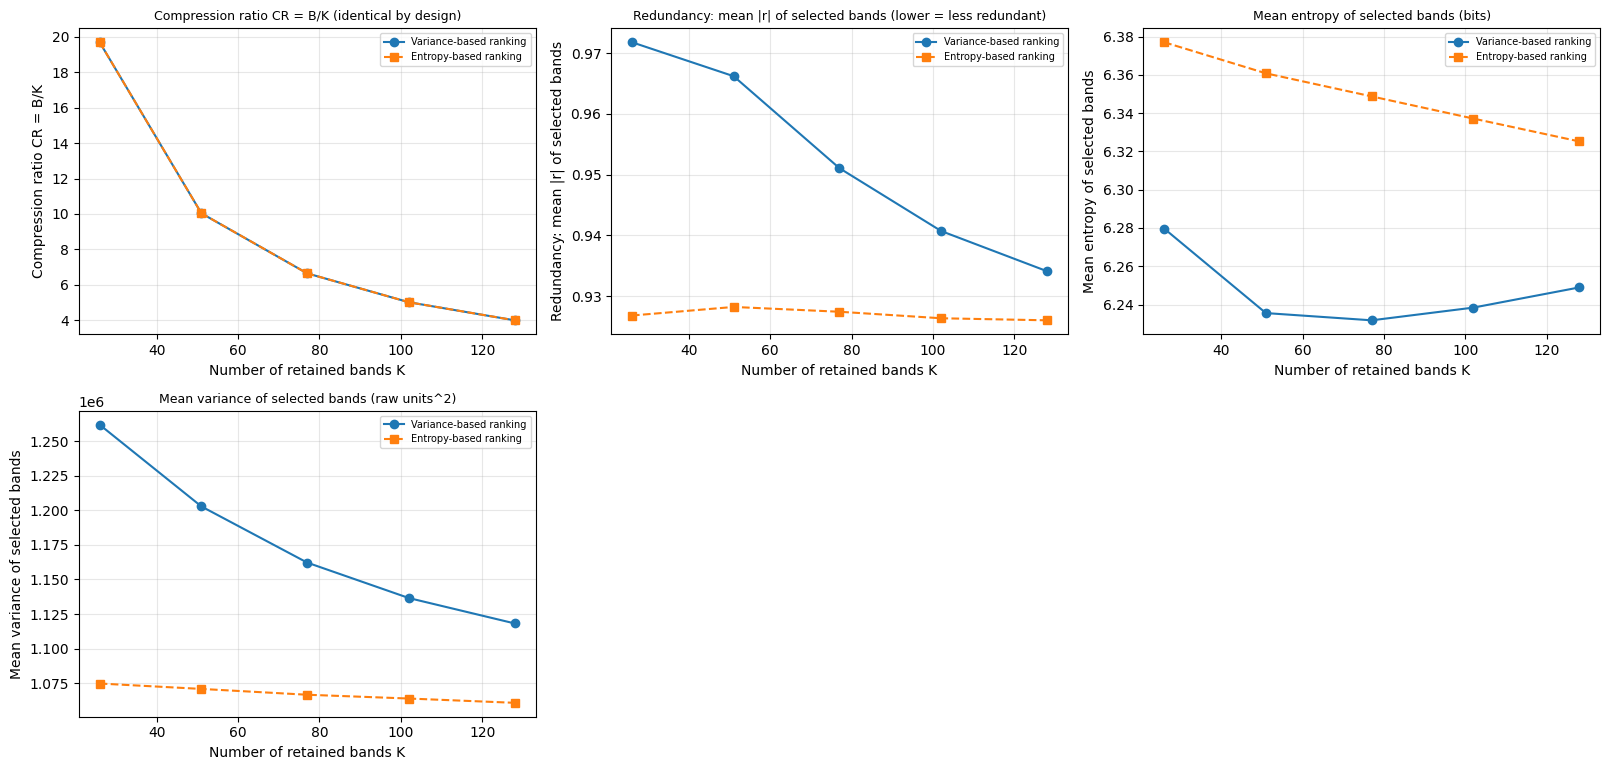

saved: /kaggle/working/hsi_ranking_outputs/figures/27b_selected_band_indices_comparison.png


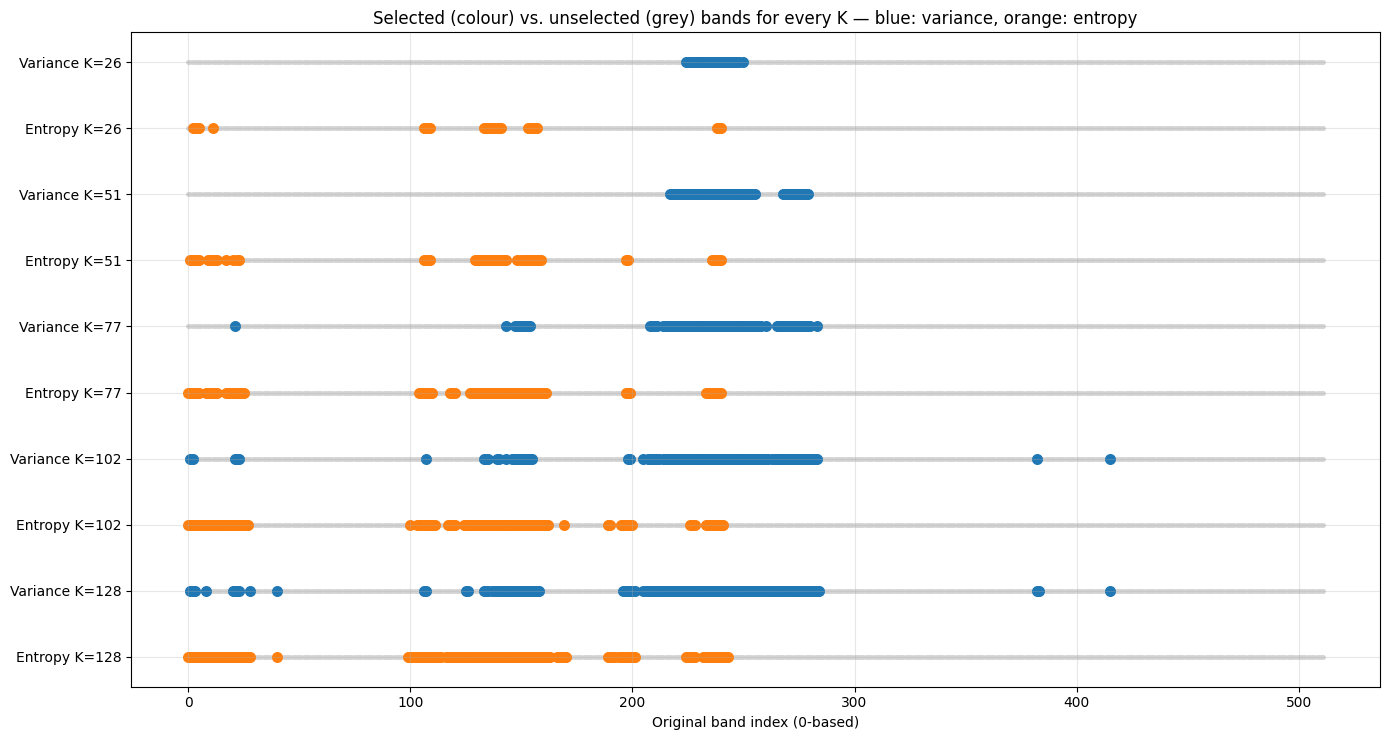

saved: /kaggle/working/hsi_ranking_outputs/figures/27c_spectral_profiles_selected_bands.png


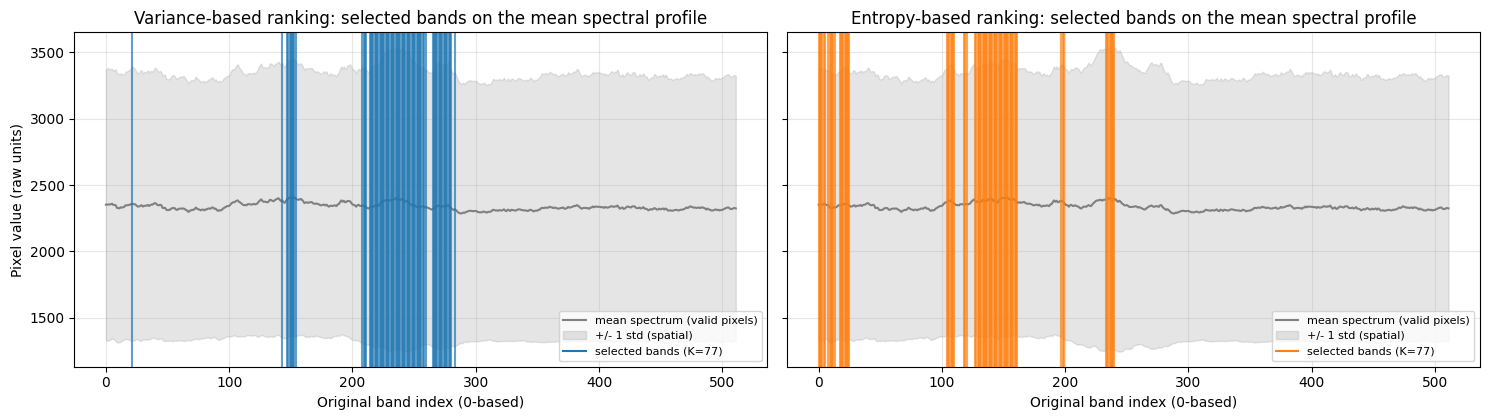

saved: /kaggle/working/hsi_ranking_outputs/figures/27d_histograms_representative_selected_bands.png


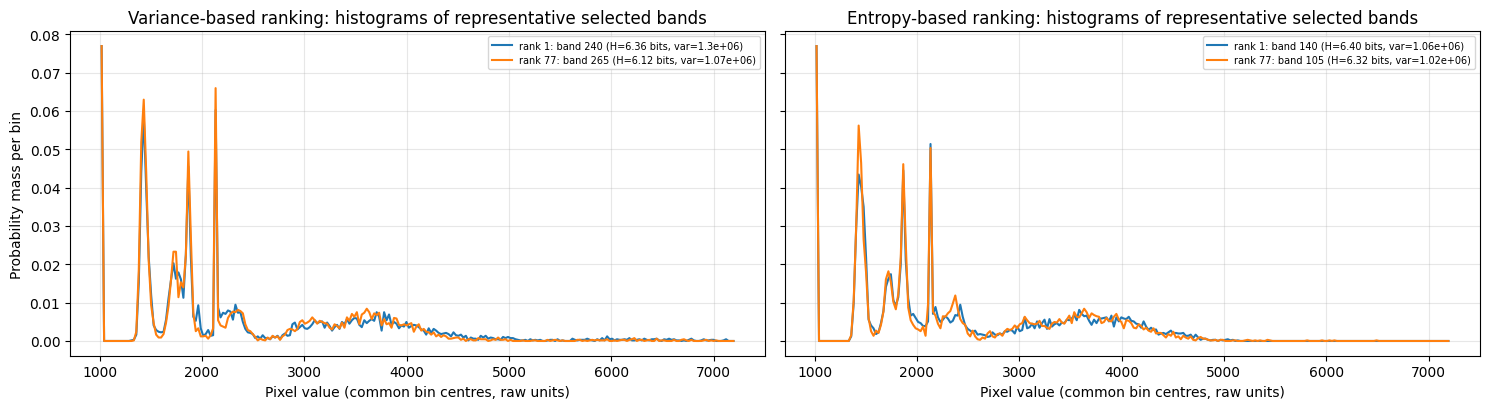

saved: /kaggle/working/hsi_ranking_outputs/figures/27e_runtime_memory.png


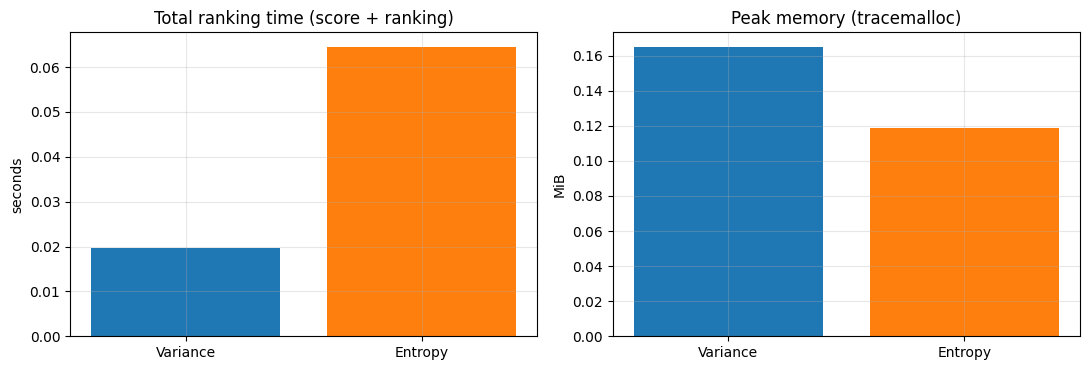

Confusion matrices N/A: no valid pixel-level label map found


In [36]:
# --- 1) metric comparison vs K ---
plot_list = [("CR", "Compression ratio CR = B/K (identical by design)"), ("redundancy", "Redundancy: mean |r| of selected bands (lower = less redundant)"),
             ("mean_selected_entropy", "Mean entropy of selected bands (bits)"), ("mean_selected_variance", "Mean variance of selected bands (raw units^2)")]
if RECON_OK:
    plot_list += [("PSNR_omitted", "PSNR (dB), omitted bands [recon]"), ("SSIM_omitted", "SSIM, omitted bands [recon]"),
                  ("SAM_deg", "SAM (deg) [recon] (lower = better)"), ("MAE_omitted", "MAE, omitted bands [recon] (lower = better)"),
                  ("MRE_omitted", "Mean relative error, omitted bands [recon]")]
if CLS is not None:
    plot_list += [("OA", "Overall accuracy [labels]"), ("AA", "Average accuracy [labels]"), ("Kappa", "Cohen's kappa [labels]")]
ncol = 3; nrow = math.ceil(len(plot_list) / ncol)
fig, axs = plt.subplots(nrow, ncol, figsize=(5.4 * ncol, 3.9 * nrow)); axs = np.atleast_1d(axs).ravel()
for ax, (col, ttl) in zip(axs, plot_list):
    for m, mk in (("Variance", "o-"), ("Entropy", "s--")):
        d = RES[RES.method == m].sort_values("K"); ax.plot(d.K, d[col].replace([np.inf], np.nan), mk, color=COLORS[m], label=f"{m}-based ranking")
    if CLS is not None and col in ("OA", "AA", "Kappa"): ax.axhline(BASELINE[col], color="gray", ls=":", label=f"all {B_V} bands")
    ax.set_xlabel("Number of retained bands K"); ax.set_ylabel(ttl.split(" [")[0].split(" (")[0]); ax.set_title(ttl, fontsize=9); ax.legend(fontsize=7)
for ax in axs[len(plot_list):]: ax.axis("off")
plt.tight_layout(); savefig("27a_metric_comparison_vs_K"); plt.show()

# --- 2) comparison of selected band indices ---
fig, ax = plt.subplots(figsize=(14, 0.55 * len(K_LIST) * 2 + 2)); y = 0; yt, yl = [], []
for K in K_LIST:
    for m in METHODS:
        ax.scatter(VALID_IDX, np.full(B_V, y), s=6, color="lightgray")
        o = VALID_IDX[SEL[m][K]]; ax.scatter(o, np.full(K, y), s=48, color=COLORS[m]); yt.append(y); yl.append(f"{m} K={K}"); y += 1
ax.set_yticks(yt); ax.set_yticklabels(yl); ax.invert_yaxis(); ax.set_xlabel("Original band index (0-based)")
ax.set_title("Selected (colour) vs. unselected (grey) bands for every K — blue: variance, orange: entropy")
plt.tight_layout(); savefig("27b_selected_band_indices_comparison"); plt.show()

# --- 3) spectral profile with selected bands, and histograms of representative selected bands ---
mean_sp = stats.loc[VALID_IDX, "mean"].values; std_sp = stats.loc[VALID_IDX, "std"].values
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for a, m in zip(ax, METHODS):
    a.plot(XL, mean_sp, color="gray", label="mean spectrum (valid pixels)"); a.fill_between(XL, mean_sp - std_sp, mean_sp + std_sp, color="gray", alpha=0.2, label="+/- 1 std (spatial)")
    for p in SEL[m][K_REF]: a.axvline(XL[p], color=COLORS[m], alpha=0.7)
    a.plot([], [], color=COLORS[m], label=f"selected bands (K={K_REF})"); a.set_xlabel(XLABEL); a.set_title(f"{m}-based ranking: selected bands on the mean spectral profile"); a.legend(fontsize=8)
ax[0].set_ylabel("Pixel value (raw units)")
plt.tight_layout(); savefig("27c_spectral_profiles_selected_bands"); plt.show()

edges = make_edges(CONFIG["entropy_bins"]); centers = 0.5 * (edges[:-1] + edges[1:])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for a, m in zip(ax, METHODS):
    s = SEL[m][K_REF]
    for p, l in ((s[0], "rank 1"), (s[-1], f"rank {K_REF}")):
        pm, _ = band_pmf(VALID_IDX[p], edges); a.plot(centers, pm, label=f"{l}: band {VALID_IDX[p]} (H={ENT[p]:.2f} bits, var={VAR[p]:.3g})")
    a.set_xlabel("Pixel value (common bin centres, raw units)"); a.set_title(f"{m}-based ranking: histograms of representative selected bands"); a.legend(fontsize=7)
ax[0].set_ylabel("Probability mass per bin")
plt.tight_layout(); savefig("27d_histograms_representative_selected_bands"); plt.show()

# --- 4) runtime / memory ---
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, col, ttl, yl_ in ((ax[0], "total_time_s", "Total ranking time (score + ranking)", "seconds"), (ax[1], "peak_memory_MiB", "Peak memory (tracemalloc)", "MiB")):
    a.bar(TIMING.method, TIMING[col], color=[COLORS[m] for m in TIMING.method]); a.set_ylabel(yl_); a.set_title(ttl)
plt.tight_layout(); savefig("27e_runtime_memory"); plt.show()

# --- 5) confusion matrices ---
if CLS is not None:
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, m in zip(ax, METHODS):
        row = RES[(RES.method == m) & (RES.K == K_REF)].iloc[0]; cmn = CM[(m, K_REF)].astype(float); cmn = cmn / np.maximum(cmn.sum(axis=1, keepdims=True), 1)
        im = a.imshow(cmn, vmin=0, vmax=1, cmap="Blues"); a.set_xticks(range(len(CLS["classes"]))); a.set_xticklabels(CLS["classes"]); a.set_yticks(range(len(CLS["classes"]))); a.set_yticklabels(CLS["classes"])
        a.set_xlabel("Predicted class"); a.set_ylabel("True class"); a.set_title(f"{m}-based, K={K_REF}\nOA={row.OA:.3f}, AA={row.AA:.3f}, kappa={row.Kappa:.3f}"); a.grid(False)
        plt.colorbar(im, ax=a, fraction=0.046, label="row-normalised fraction")
    plt.tight_layout(); savefig("27f_confusion_matrices"); plt.show()
else:
    print("Confusion matrices N/A:", CLS_REASON)

## Section 28 — Final findings and limitations

The cell below converts the **measured** table into plain statements, metric by metric and $K$ by $K$. For metrics with a direction (e.g. lower SAM is better) it names the method with the better value; for descriptive metrics it names the method with the *higher* value; identical values are ties. It deliberately declares **no overall winner**: the metrics are not equally important, several are correlated, and both methods were run once (deterministic) on one cube, so no significance can be assessed.

**Standing limitations**
1. One cube / one dataset: conclusions may not transfer to other scenes or sensors.
2. Variance and entropy are single-band scores: Top-K sets may be spectrally bunched and redundant, and noisy bands can score high on both. Neither score uses class information.
3. Entropy depends on the histogram design (bins, common range); Section 18 quantifies the dependence on bin count. The common global range lets one extreme band compress all others.
4. CR and bpp depend only on $K$, $B$ and the bit depth, so they are **identical for both methods by construction**; they describe theoretical band-dropping storage, not an encoded file.
5. Reconstruction metrics (if available) depend jointly on the selected set and the linear-interpolation baseline; they are not a property of the ranking alone.
6. Redundancy is computed from sampled pixels; it is an evaluation read-out only.
7. Classification: one classifier, one split (a spatially separated block split if possible, otherwise optimistic random split); labels are used only for evaluation.
8. `tracemalloc` memory and wall-clock times depend on hardware and libraries.
9. Constant bands are excluded from both rankings (listed in Section 8); invalid pixels are excluded for both methods.

**What this cell does:** turns the measured results into a metric-by-metric statement of which method has the better (or higher) value at every K.  
**Why it is needed:** to give a factual, uncheatable summary without declaring a universal winner.  
**How it works:** compares the two methods' numbers per metric and K, respecting whether lower or higher is better; also prints the shared-band counts and the Spearman correlation between the variance and entropy scores.  
**Expected output:** a table of verdict words per metric and K (saved as CSV) and a reminder of how to interpret it.

In [37]:
HIB = {"PSNR_all": True, "PSNR_omitted": True, "SSIM_all": True, "SSIM_omitted": True, "SAM_deg": False, "MAE_all": False, "MAE_omitted": False,
       "MRE_omitted": False, "redundancy": False, "OA": True, "AA": True, "Kappa": True,
       "mean_selected_entropy": None, "mean_selected_variance": None}      # None = descriptive (higher is not 'better')

def verdict(col, K):
    a = RES[(RES.method == "Variance") & (RES.K == K)][col].iloc[0]; b = RES[(RES.method == "Entropy") & (RES.K == K)][col].iloc[0]
    if not (np.isfinite(a) and np.isfinite(b)): return "N/A" if not (np.isinf(a) and np.isinf(b)) else "tie"
    if np.isclose(a, b, rtol=1e-9, atol=1e-12): return "tie"
    if HIB[col] is None: return "Variance higher" if a > b else "Entropy higher"
    return "Variance better" if (a > b) == HIB[col] else "Entropy better"

V = pd.DataFrame({col: [verdict(col, K) for K in K_LIST] for col in HIB}, index=[f"K={K}" for K in K_LIST]).T
tv = TIMING.set_index("method")
V.loc["total_time_s (single measurement)"] = ["Variance faster" if tv.loc["Variance", "total_time_s"] < tv.loc["Entropy", "total_time_s"] else "Entropy faster"] * len(K_LIST)
V.to_csv(TAB_DIR / "metric_by_metric_comparison.csv")
print("Metric-by-metric comparison (measured; single deterministic run each, differences are NOT tested for significance):\n")
print(V.to_string())
print("\nShared bands per K:", {K: len(overlap[K]) for K in K_LIST}, "| Rank correlation of the two full rankings (Spearman on scores):", round(float(spearmanr(VAR, ENT)[0]), 4))
print("\nNo overall winner is declared. Higher variance or higher entropy does not by itself imply better classification or reconstruction;")
print("read the trade-offs (e.g. redundancy vs. accuracy vs. run time) in the context of the limitations listed above.")

Metric-by-metric comparison (measured; single deterministic run each, differences are NOT tested for significance):

                                              K=26             K=51             K=77            K=102            K=128
PSNR_all                                       N/A              N/A              N/A              N/A              N/A
PSNR_omitted                                   N/A              N/A              N/A              N/A              N/A
SSIM_all                                       N/A              N/A              N/A              N/A              N/A
SSIM_omitted                                   N/A              N/A              N/A              N/A              N/A
SAM_deg                                        N/A              N/A              N/A              N/A              N/A
MAE_all                                        N/A              N/A              N/A              N/A              N/A
MAE_omitted                                    N/A

## Section 29 — Exporting selected bands, indices, tables and figures

**Output folder structure**
```
hsi_ranking_outputs/
├── figures/          *.png   all plots
├── tables/           *.csv/json  band statistics, bin-sensitivity, final_comparison_K*.csv, all_results_long.csv, runtime_memory.csv, verdicts, classification tables
├── rankings/         variance_ranking_all_bands.csv, entropy_ranking_all_bands.csv   (complete sorted rankings, original indices)
├── selected_bands/   <method>_top<K>_selected_bands.csv   (0-/1-based original indices, rank, score, retention %)
├── reduced_cubes/    <method>_K<K>_reduced_cube_HWK.npy   (H x W x K, channels in ascending original band order)
├── reports/          dataset_inspection_report.json, run_summary.json, classification_reports.txt, README.txt
└── config/           config.json, environment.json
```

**What this cell does:** saves the configuration, environment, run summary, README and zips every output.  
**Why it is needed:** reproducibility and easy download of all deliverables.  
**How it works:** writes JSON/text files and creates one zip archive of the output folder.  
**Expected output:** environment details, the zip path and a file count per output folder.

In [38]:
CFG_OUT = dict(CONFIG, resolved_K_list=K_LIST, K_REF=K_REF, image_file=str(IMG_PATH), valid_band_count=B_V, constant_bands_excluded=CONST_BANDS.tolist(),
               original_bits=ORIG_BITS, data_range_DR=DR, variance_convention="population (ddof=0), raw values, all valid pixels",
               entropy_histogram=dict(bins=CONFIG["entropy_bins"], range=[ENT_LO, ENT_HI], log_base=2, edges="common equal-width"),
               reconstruction=("linear interpolation over " + COORD_KIND) if RECON_OK else "N/A: " + RECON_REASON,
               classification=SPLIT_TYPE if CLS is not None else "N/A: " + CLS_REASON, n_sampled_pixels_for_redundancy=int(n_s))
(CFG_DIR / "config.json").write_text(json.dumps(CFG_OUT, indent=2, default=str))
env = dict(python=sys.version, platform=platform.platform(), processor=platform.processor(), cpu_count=os.cpu_count(),
           ram_GiB=round(psutil.virtual_memory().total / 2**30, 2) if psutil else None, numpy=np.__version__, scipy=scipy.__version__,
           sklearn=sklearn.__version__, skimage=skimage.__version__, pandas=pd.__version__, matplotlib=matplotlib.__version__)
(CFG_DIR / "environment.json").write_text(json.dumps(env, indent=2))
(REP_DIR / "run_summary.json").write_text(json.dumps(dict(K_list=K_LIST, reference_K=K_REF, methods=METHODS, reconstruction_enabled=bool(RECON_OK),
                                                         classification_enabled=CLS is not None, labels_used_for_ranking=False), indent=2))
(REP_DIR / "README.txt").write_text("Outputs of the variance vs entropy ranking-based hyperspectral band-selection notebook.\n"
    "All numbers are measured by the notebook run; none are pre-filled. Re-run top to bottom to reproduce.\n"
    f"Seed={CONFIG['seed']}, K list={K_LIST}, entropy bins={CONFIG['entropy_bins']}.\n")
zip_path = shutil.make_archive(str(OUT_ROOT / "hsi_ranking_results"), "zip", OUT)
print("Environment:", json.dumps(env, indent=1)); print("\nZipped results ->", zip_path)
print("Files saved:", sum(1 for p in OUT.rglob("*") if p.is_file()))
for d in DIRS.values(): print(f"  {d.name:<15} {len(list(d.glob('*'))):>3} files")

Environment: {
 "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
 "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
 "processor": "x86_64",
 "cpu_count": 4,
 "ram_GiB": 31.35,
 "numpy": "2.1.3",
 "scipy": "1.16.3",
 "sklearn": "1.6.1",
 "skimage": "0.25.2",
 "pandas": "2.3.3",
 "matplotlib": "3.10.0"
}

Zipped results -> /kaggle/working/hsi_ranking_results.zip
Files saved: 48
  figures          11 files
  tables           10 files
  rankings          2 files
  selected_bands   10 files
  reduced_cubes    10 files
  reports           3 files
  config            2 files


## Workflow summary (first cell → last cell)

1. **Section 3:** libraries and one `CONFIG` dictionary (Top-K, bins, split, paths); output folders are created.
2. **Section 4–5:** the dataset folder is located and every file, format, shape and dtype is listed; label-like files and split folders are reported.
3. **Section 6:** one cube is loaded, converted to a band-first array (original band index kept), wavelengths and bit depth are read, labels are looked for.
4. **Section 7–8:** raw data is inspected; invalid pixels are masked for everyone; constant bands are listed and excluded; the valid-band mapping and fixed data range are fixed.
5. **Section 9:** the cube is viewed as a bands × pixels matrix; a sampled correlation matrix is prepared for the redundancy *metric*.
6. **Section 10:** retention percentages become integer K values shared by both methods.
7. **Section 11–15 (Model A):** population variance per band → descending ranking → Top-K → exports → plots.
8. **Section 16–21 (Model B):** common-bin histogram → probability masses → Shannon entropy → descending ranking → Top-K → exports → plots (+ bin-count sensitivity).
9. **Section 22–23:** reconstruction metrics (only with real wavelengths) and storage / redundancy / information metrics for every method and K.
10. **Section 24:** one fixed SVM with a spatially separated split gives OA/AA/κ (labels used only here).
11. **Section 25:** runtime and memory of both pipelines.
12. **Section 26–27:** side-by-side comparison tables and charts.
13. **Section 28:** measured, metric-by-metric statements and the limitations (no overall winner).
14. **Section 29:** everything is exported and zipped.